# Screening for Diabetes and Prediabetes from Self-Reported Health Indicators

### Problem statement
Diabetes affects a large share of adults, and a substantial fraction of people with diabetes or prediabetes are unaware of their condition. Laboratory tests (HbA1c, fasting glucose) are definitive but require a clinic visit. A model that flags likely cases from simple self-reported answers like blood pressure, cholesterol, BMI, general health, physical activity, income; could serve as a low-cost **pre-screening** step that directs people toward testing.

This notebook frames that question as a **binary classification task**: predict `Diabetes_binary` (0 = no diabetes, 1 = prediabetes or diabetes) from 21 health, lifestyle and socioeconomic indicators collected by the CDC's Behavioral Risk Factor Surveillance System (BRFSS).



## 1. Environment setup and reproducibility

All randomness (Python, NumPy, TensorFlow, and every scikit-learn estimator) is controlled by a single `SEED`, and TensorFlow op determinism is enabled where supported. Figures and tables are saved to disk for the report.

`FAST_MODE` is a smoke-test switch: setting the environment variable `FAST=1` shrinks samples, search iterations and epochs. **Leave it off for the real run.**

In [1]:
!pip install -q ucimlrepo

In [2]:
# !pip install -q ucimlrepo seaborn   # uncomment on a fresh Colab / local environment
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, learning_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             classification_report, balanced_accuracy_score)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("Op determinism not available:", e)

FAST_MODE = os.environ.get("FAST", "0") == "1"
CFG = dict(
    TUNE_SAMPLE = 8_000 if FAST_MODE else 60_000,   # rows used inside hyperparameter search
    LC_SAMPLE   = 8_000 if FAST_MODE else 80_000,   # rows used for learning curves
    N_ITER      = 3     if FAST_MODE else 20,       # RandomizedSearch iterations per model
    EPOCHS      = 3     if FAST_MODE else 40,       # max epochs (early stopping ends sooner)
    N_BOOT      = 50    if FAST_MODE else 500,      # bootstrap resamples for confidence intervals
    PI_SAMPLE   = 3_000 if FAST_MODE else 20_000,   # rows for permutation importance
)

FIG_DIR, RES_DIR, MODEL_DIR = "figures", "results", "models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")

sns.set_theme(style="whitegrid", context="notebook")
print(f"FAST_MODE={FAST_MODE}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__} | tensorflow {tf.__version__}")
print("GPUs:", tf.config.list_physical_devices("GPU"))

FAST_MODE=False
numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1 | tensorflow 2.21.0
GPUs: []


## 2. Loading the data

The dataset is *CDC Diabetes Health Indicators* (UCI Machine Learning Repository, id 891), fetched with the official `ucimlrepo` package so that the notebook is reproducible. It is derived from the CDC's BRFSS telephone survey of US adults, and each row is one respondent. Setting the environment variable `DATA_CSV` to a local CSV with the same columns overrides the download (useful offline).

In [3]:
TARGET = "Diabetes_binary"
csv_override = os.environ.get("DATA_CSV")
if csv_override:
    df_raw = pd.read_csv(csv_override)
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=891)
    df_raw = pd.concat([ds.data.features, ds.data.targets], axis=1)
    print(ds.metadata.get("name"), "|", ds.metadata.get("num_instances"), "instances")
df_raw = df_raw.drop(columns=[c for c in ["ID"] if c in df_raw.columns])
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head()

CDC Diabetes Health Indicators | 253680 instances
Shape: 253,680 rows × 22 columns


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [4]:
try:
    display(ds.variables[["name", "role", "type", "description"]])
except NameError:
    print("Variable metadata only available when fetched via ucimlrepo.")

,name,role,type,description
0,ID,ID,Integer,Patient ID
1,Diabetes_binary,Target,Binary,0 = no diabetes 1 = prediabetes or diabetes
2,HighBP,Feature,Binary,0 = no high BP 1 = high BP
3,HighChol,Feature,Binary,0 = no high cholesterol 1 = high cholesterol
4,CholCheck,Feature,Binary,0 = no cholesterol check in 5 years 1 = yes ch...
5,BMI,Feature,Integer,Body Mass Index
6,Smoker,Feature,Binary,Have you smoked at least 100 cigarettes in you...
7,Stroke,Feature,Binary,(Ever told) you had a stroke. 0 = no 1 = yes
8,HeartDiseaseorAttack,Feature,Binary,coronary heart disease (CHD) or myocardial inf...
9,PhysActivity,Feature,Binary,physical activity in past 30 days - not includ...


## 3. Data audit

This section checks the size requirement, data types, value ranges, missing values, class balance and duplicates. The columns fall into three types. **Binary** indicators (0/1) cover conditions and behaviours such as high blood pressure or smoking. **Ordinal** scales cover general health (1 = excellent … 5 = poor), age in 13 five-year bands, education (1–6) and income (1–8). **Counts and continuous** values cover BMI and the number of days in the past 30 with poor mental or physical health.

In [5]:
BINARY = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
          "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
ORDINAL = ["GenHlth", "Age", "Education", "Income"]
CONTINUOUS = ["BMI", "MentHlth", "PhysHlth"]
RAW_FEATURES = BINARY + ORDINAL + CONTINUOUS
assert set(RAW_FEATURES + [TARGET]) == set(df_raw.columns), set(df_raw.columns) ^ set(RAW_FEATURES + [TARGET])

audit = pd.DataFrame({
    "type": ["binary" if c in BINARY else "ordinal" if c in ORDINAL else "continuous" if c in CONTINUOUS else "target" for c in df_raw.columns],
    "dtype": df_raw.dtypes.astype(str), "n_missing": df_raw.isna().sum(), "n_unique": df_raw.nunique(),
    "min": df_raw.min(), "max": df_raw.max(), "mean": df_raw.mean().round(3)})
audit.to_csv(os.path.join(RES_DIR, "data_audit.csv"))
print(f"Meets the ≥20,000-row requirement: {len(df_raw) >= 20_000} ({len(df_raw):,} rows)")
print(f"Total missing values: {df_raw.isna().sum().sum()}")
audit

Meets the ≥20,000-row requirement: True (253,680 rows)
Total missing values: 0


,type,dtype,n_missing,n_unique,min,max,mean
HighBP,binary,int64,0,2,0,1,0.429
HighChol,binary,int64,0,2,0,1,0.424
CholCheck,binary,int64,0,2,0,1,0.963
BMI,continuous,int64,0,84,12,98,28.382
Smoker,binary,int64,0,2,0,1,0.443
Stroke,binary,int64,0,2,0,1,0.041
HeartDiseaseorAttack,binary,int64,0,2,0,1,0.094
PhysActivity,binary,int64,0,2,0,1,0.757
Fruits,binary,int64,0,2,0,1,0.634
Veggies,binary,int64,0,2,0,1,0.811


In [6]:
n_dup = df_raw.duplicated().sum()
n_dup_feat = df_raw.drop(columns=[TARGET]).duplicated().sum()
conflict = df_raw.groupby(RAW_FEATURES)[TARGET].nunique()
print(f"Exact duplicate rows:                        {n_dup:,} ({n_dup/len(df_raw):.1%})")
print(f"Rows whose feature vector appears earlier:   {n_dup_feat:,} ({n_dup_feat/len(df_raw):.1%})")
print(f"Feature profiles that occur with BOTH labels: {(conflict > 1).sum():,}")

Exact duplicate rows:                        24,206 (9.5%)
Rows whose feature vector appears earlier:   25,772 (10.2%)
Feature profiles that occur with BOTH labels: 1,566


**Duplicate rows (keep or drop?)** Every feature is binary, ordinal or a small integer, so two different respondents can easily give identical answers; a healthy 30 year old with no conditions is a very common profile. Removing duplicates would therefore delete real people and distort the population distribution, especially for common low-risk profiles. The main analysis **keeps all rows**. Because identical rows can fall on both sides of a split, part 10.4 checks whether test performance differs between rows that have an exact twin in training and rows that do not. Feature profiles that occur with both labels also show that the task has irreducible noise: the same answers can belong to people with and without diabetes.

## 4. Exploratory data analysis

### 4.1 Target distribution

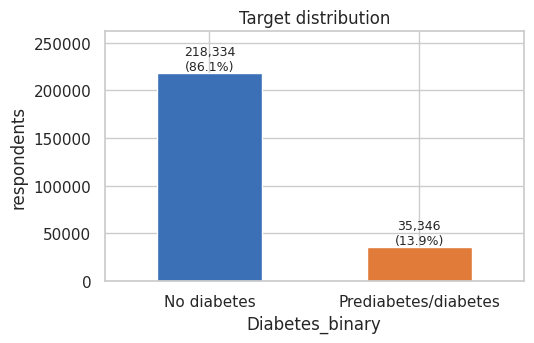

Positive rate: 13.933% → imbalance ratio ≈ 1:6.2


In [7]:
vc = df_raw[TARGET].value_counts().sort_index()
ax = vc.rename({0: "No diabetes", 1: "Prediabetes/diabetes"}).plot.bar(color=["#3b6fb6", "#e07b39"], figsize=(5.5, 3.6), rot=0)
for p, v in zip(ax.patches, vc.values):
    ax.annotate(f"{v:,}\n({v/len(df_raw):.1%})", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
ax.set(title="Target distribution", ylabel="respondents", ylim=(0, vc.max() * 1.2))
plt.tight_layout(); savefig("04_target_distribution"); plt.show()
POS_RATE = df_raw[TARGET].mean()
print(f"Positive rate: {POS_RATE:.3%} → imbalance ratio ≈ 1:{(1-POS_RATE)/POS_RATE:.1f}")

**Interpretation.** Only 35,346 respondents (13.9%) have prediabetes or diabetes, against 218,334 (86.1%) without, an imbalance of about 1:6.2. A model that always predicts “no diabetes” would reach 86.1% accuracy while detecting nobody, so accuracy is misleading here. Evaluation therefore focuses on ROC-AUC, PR-AUC (chance level ≈ 0.14), recall and F1, and the imbalance is handled explicitly through class weighting, threshold tuning and stratified splits.



### 4.2 Prevalence by feature
For binary and ordinal features, each chart shows the share of respondents at each level who have prediabetes or diabetes; the dashed line is the overall rate. Continuous features are shown as distributions split by class.

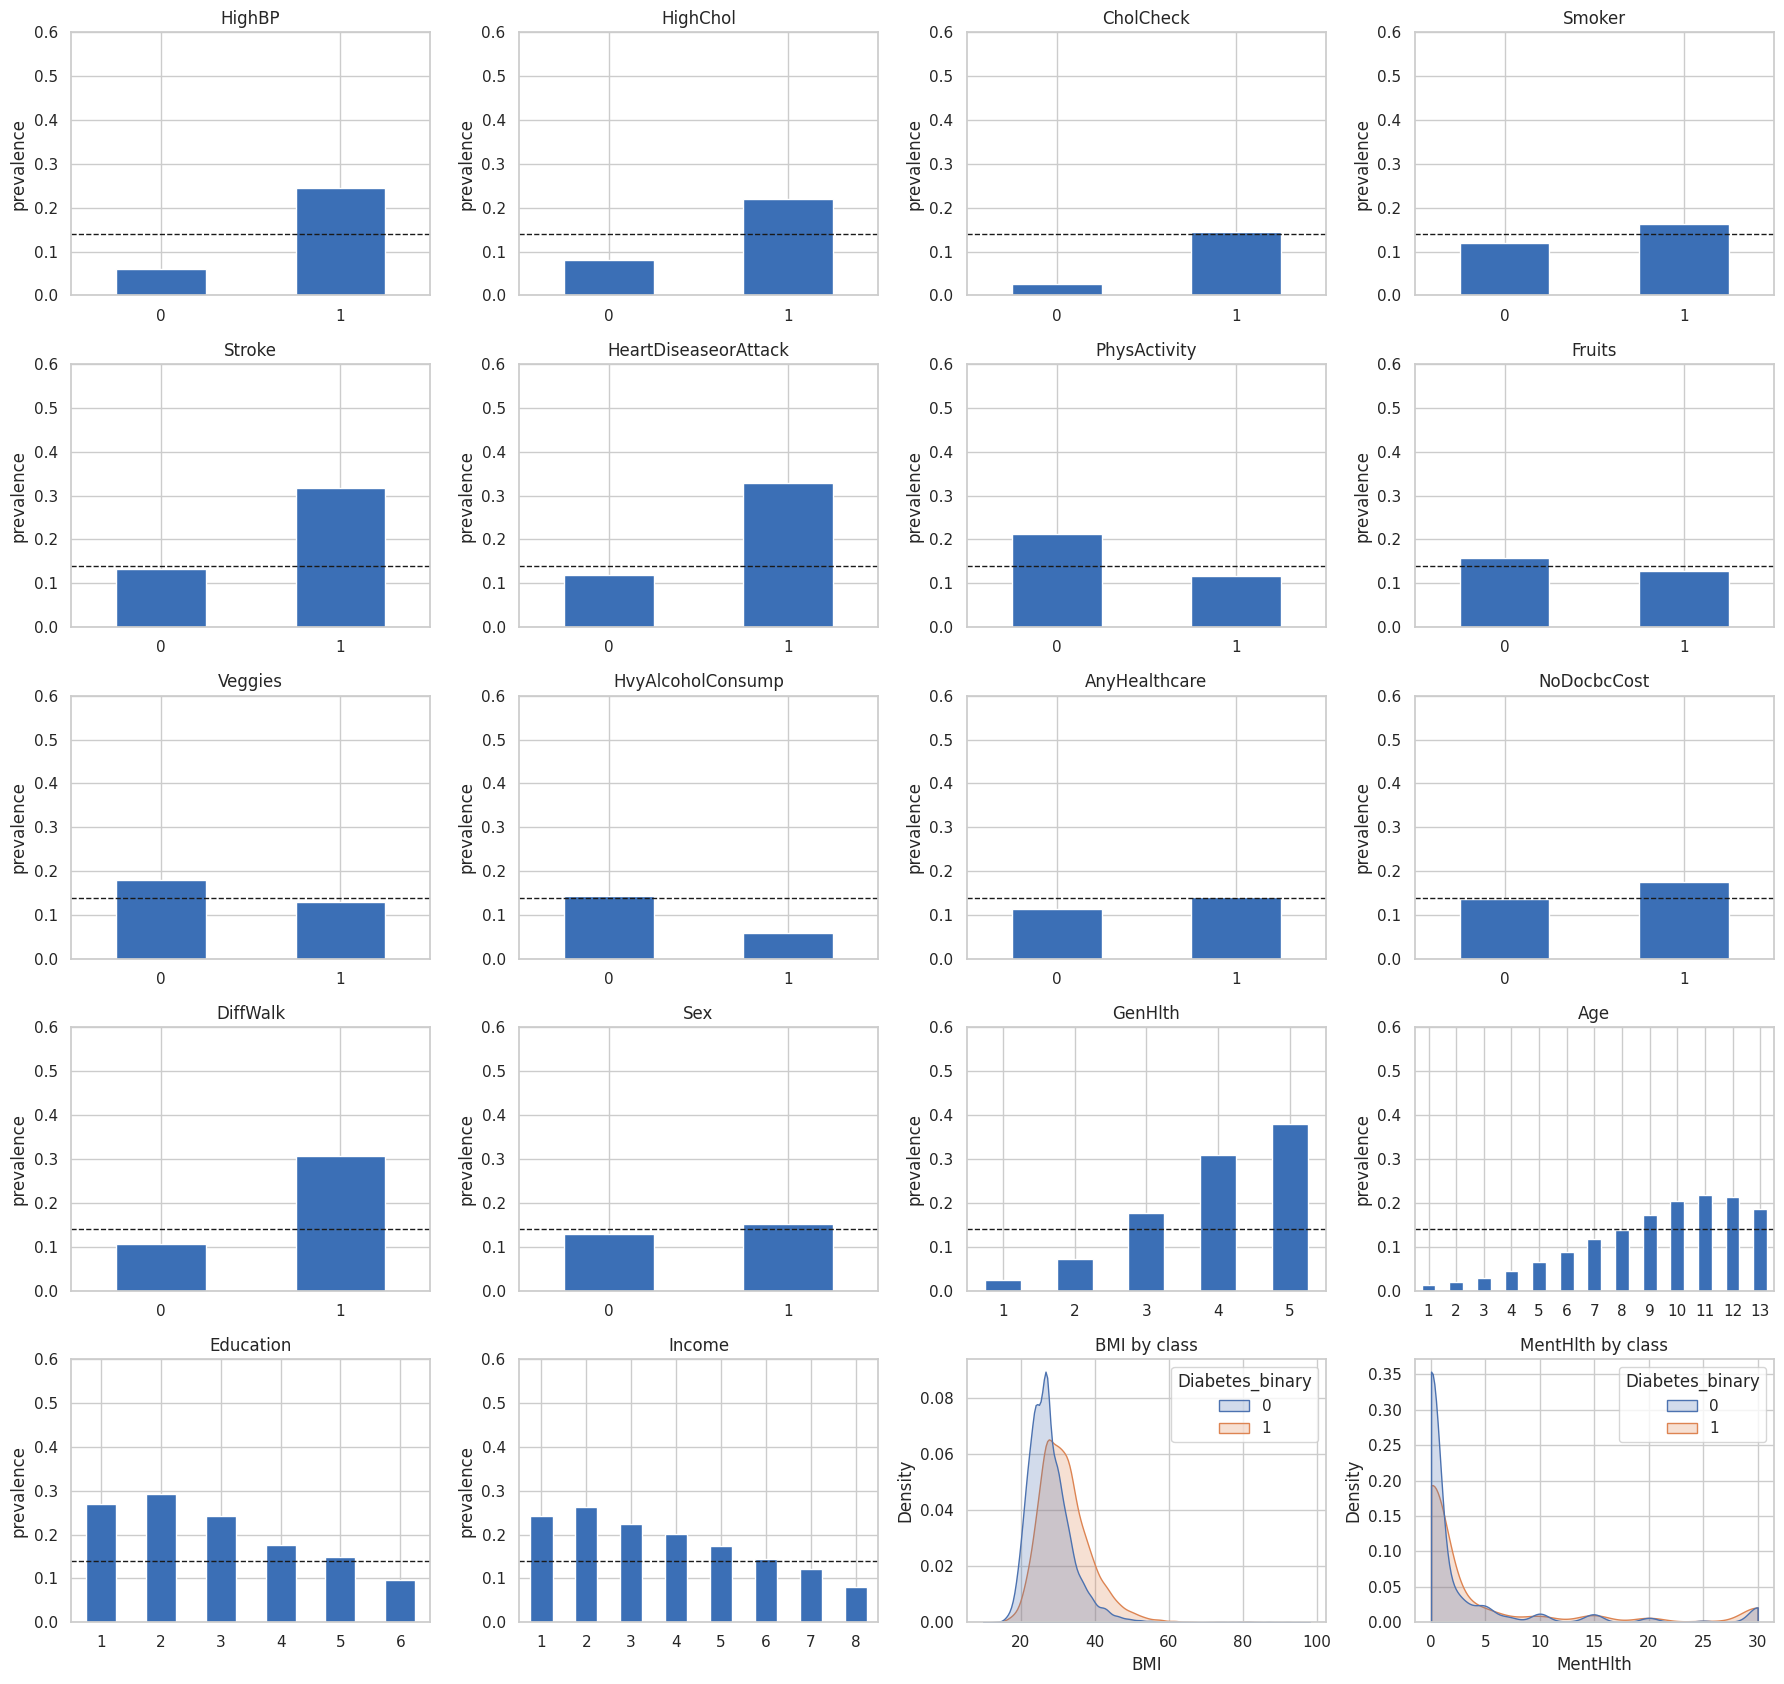

In [8]:
fig, axes = plt.subplots(5, 4, figsize=(18, 17))
axes = axes.ravel()
for ax, col in zip(axes, BINARY + ORDINAL):
    rate = df_raw.groupby(col)[TARGET].mean()
    rate.plot.bar(ax=ax, color="#3b6fb6", rot=0)
    ax.axhline(POS_RATE, ls="--", color="k", lw=1)
    ax.set(title=col, xlabel="", ylabel="prevalence", ylim=(0, max(0.6, rate.max() * 1.1)))
for ax, col in zip(axes[len(BINARY + ORDINAL):], CONTINUOUS):
    sns.kdeplot(data=df_raw.sample(min(60_000, len(df_raw)), random_state=SEED), x=col, hue=TARGET,
                common_norm=False, fill=True, ax=ax, clip=(0, df_raw[col].max()))
    ax.set_title(f"{col} by class")
for ax in axes[len(RAW_FEATURES):]:
    ax.axis("off")
plt.tight_layout(); savefig("04_prevalence_by_feature"); plt.show()

### 4.3 Strength of association
Two measures are used because the features are of mixed type. For binary and ordinal features, **Cramér's V** (from the χ² test) measures association with the target on a 0–1 scale. For all features, the **point-biserial / Spearman correlation** with the target gives a signed view, and a feature–feature Spearman heatmap reveals redundancy.

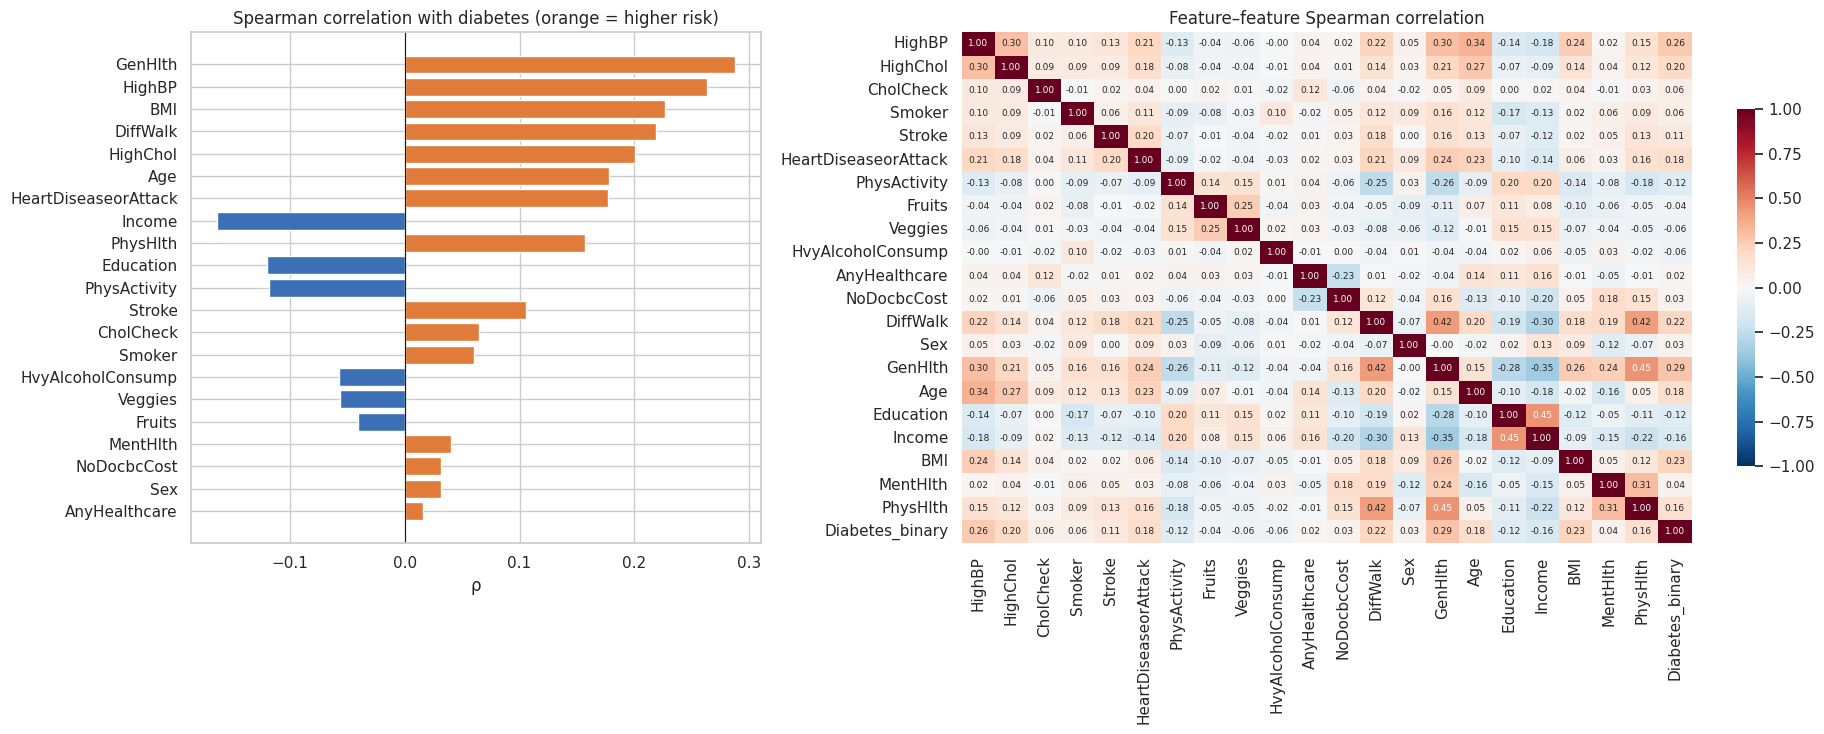

,feature,type,cramers_v,spearman_r
0,GenHlth,ordinal,0.299,0.288
1,HighBP,binary,0.263,0.263
2,BMI,continuous,NaN,0.226
3,DiffWalk,binary,0.218,0.218
4,HighChol,binary,0.200,0.200
5,Age,ordinal,0.186,0.178
6,HeartDiseaseorAttack,binary,0.177,0.177
7,Income,ordinal,0.166,-0.163
8,PhysHlth,continuous,NaN,0.157
9,Education,ordinal,0.126,-0.120


In [9]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt((chi2 / n) / max(1, min(r - 1, k - 1)))

assoc = pd.DataFrame({
    "feature": RAW_FEATURES,
    "type": ["binary" if c in BINARY else "ordinal" if c in ORDINAL else "continuous" for c in RAW_FEATURES],
    "cramers_v": [cramers_v(df_raw[c], df_raw[TARGET]) if c not in CONTINUOUS else np.nan for c in RAW_FEATURES],
    "spearman_r": [stats.spearmanr(df_raw[c], df_raw[TARGET])[0] for c in RAW_FEATURES],
}).sort_values("spearman_r", key=np.abs, ascending=False).reset_index(drop=True)
assoc.to_csv(os.path.join(RES_DIR, "association_with_target.csv"), index=False)

corr = df_raw[RAW_FEATURES + [TARGET]].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={"width_ratios": [1, 1.6]})
cols = ["#e07b39" if v > 0 else "#3b6fb6" for v in assoc["spearman_r"]]
axes[0].barh(assoc["feature"], assoc["spearman_r"], color=cols); axes[0].invert_yaxis(); axes[0].axvline(0, color="k", lw=.8)
axes[0].set(title="Spearman correlation with diabetes (orange = higher risk)", xlabel="ρ")
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1], annot=True, fmt=".2f", annot_kws={"size": 6.5}, cbar_kws={"shrink": .7})
axes[1].set_title("Feature–feature Spearman correlation")
plt.tight_layout(); savefig("04_association"); plt.show()
assoc.round(3)

**Interpretation.** With approximetly 254k rows every correlation is “significant”, so effect size is what matters. The strongest positive associations with diabetes are GenHlth (ρ ≈ 0.29), HighBP (0.26), BMI (0.23), DiffWalk (0.22), HighChol (0.20), and Age and HeartDiseaseorAttack (0.18). The strongest negative ones are Income (−0.16), Education and PhysActivity (−0.12). No single feature exceeds ρ ≈ 0.3, so the signal is spread across many moderate predictors rather than concentrated in one. That suggests combining them should outperform any single indicator.

In the heatmap, the main redundancy clusters are general health with physical-health days and difficulty walking (ρ ≈ 0.42–0.45), education with income (0.45), and high blood pressure with age (0.34). No pair is strongly collinear, so all features are kept, though correlated ones will share credit in permutation importance (part 10.3).

## 5. Feature engineering

Engineered features encode domain knowledge from clinical guidelines that models might otherwise have to rediscover:

`bmi_class` maps BMI to the WHO categories (underweight, normal, overweight, obesity I/II/III), capturing the clinically recognised step changes in risk.
`cardio_risk_count` counts cardiometabolic conditions (high blood pressure, high cholesterol, heart disease, stroke); these cluster in metabolic syndrome, which is closely linked to type 2 diabetes.
`lifestyle_score` sums healthy behaviours (physical activity, fruit, vegetables, not smoking, not drinking heavily).
`frequent_mental_distress` and `frequent_physical_distress` flag 14 or more poor-health days in the past month, the CDC's standard definitions.
`healthcare_barrier` flags respondents without coverage or who skipped a doctor because of cost; such people are less likely to have been tested.
`age_x_bmi` is an interaction: excess weight carries more risk at older ages.

Whether these features help is tested in part 7.2, not assumed.

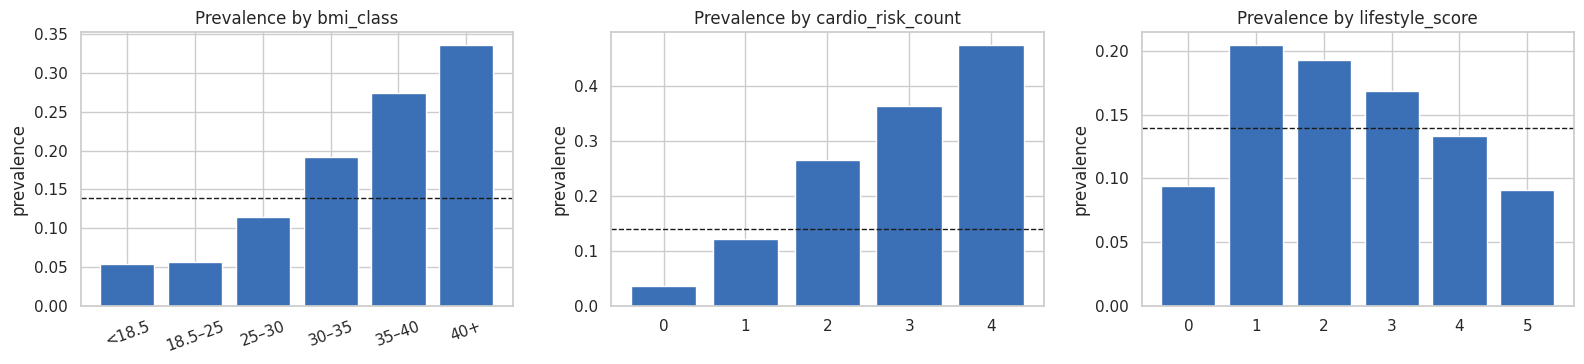

,bmi_class,cardio_risk_count,lifestyle_score,frequent_mental_distress,frequent_physical_distress,healthcare_barrier,age_x_bmi
count,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000,253680.000
mean,2.240,0.988,3.703,0.097,0.133,0.115,227.231
std,1.135,0.969,1.089,0.296,0.339,0.319,98.115
min,0.000,0.000,0.000,0.000,0.000,0.000,14.000
25%,1.000,0.000,3.000,0.000,0.000,0.000,161.000
50%,2.000,1.000,4.000,0.000,0.000,0.000,230.000
75%,3.000,2.000,5.000,0.000,0.000,0.000,290.000
max,5.000,4.000,5.000,1.000,1.000,1.000,1274.000


In [10]:
def engineer(d):
    d = d.copy()
    d["bmi_class"] = pd.cut(d["BMI"], bins=[0, 18.5, 25, 30, 35, 40, np.inf], labels=False, right=False).astype(int)
    d["cardio_risk_count"] = d[["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]].sum(axis=1)
    d["lifestyle_score"] = d["PhysActivity"] + d["Fruits"] + d["Veggies"] + (1 - d["Smoker"]) + (1 - d["HvyAlcoholConsump"])
    d["frequent_mental_distress"] = (d["MentHlth"] >= 14).astype(int)
    d["frequent_physical_distress"] = (d["PhysHlth"] >= 14).astype(int)
    d["healthcare_barrier"] = ((d["AnyHealthcare"] == 0) | (d["NoDocbcCost"] == 1)).astype(int)
    d["age_x_bmi"] = d["Age"] * d["BMI"]
    return d

ENG = ["bmi_class", "cardio_risk_count", "lifestyle_score", "frequent_mental_distress",
       "frequent_physical_distress", "healthcare_barrier", "age_x_bmi"]
df = engineer(df_raw)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, ["bmi_class", "cardio_risk_count", "lifestyle_score"]):
    r = df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(r.index.astype(str), r["mean"], color="#3b6fb6"); ax.axhline(POS_RATE, ls="--", color="k", lw=1)
    ax.set(title=f"Prevalence by {col}", ylabel="prevalence")
axes[0].set_xticks(range(6)); axes[0].set_xticklabels(["<18.5", "18.5–25", "25–30", "30–35", "35–40", "40+"], rotation=20)
plt.tight_layout(); savefig("05_engineered_features"); plt.show()
df[ENG].describe().round(3)

**Interpretation.** The composites capture clear clinical gradients:

BMI class: prevalence is about 5% for underweight and normal BMI, rises to 11% for overweight, and climbs to 33% in the highest obesity class (40+).
Cardiometabolic risk count: the steepest gradient. Prevalence rises from 3.5% with no conditions to 47% with all four, more than any single raw feature achieves.
Lifestyle score: prevalence falls from about 20% at a score of 1 to 9% at 5, as expected. The exception is a score of 0, where prevalence is unexpectedly low (≈ 9%). This small group must include heavy drinkers, so it likely reflects the heavy-drinking anomaly noted in part 4.2.

These patterns suggest the engineered features should help, especially for linear models, which is tested in part 7.2.

## 6. Stratified train / validation / test split

The data are split 70 / 15 / 15 with **stratification** on the target, so each subset keeps the ≈14% positive rate. The validation set is used for model selection, early stopping and threshold choice; the test set is touched only once, in §9. Cross-validation inside the training set uses `StratifiedKFold`.

Two preprocessing variants are defined so feature engineering can be measured. **Raw** scales the ordinal and continuous columns and passes the binary ones through. **Full** adds the engineered features. An optional one-hot encoding of the ordinal columns is tested in part 7.2, since treating age or general health as linear may be too restrictive for linear models.

In [11]:
df_trval, df_test = train_test_split(df, test_size=0.15, stratify=df[TARGET], random_state=SEED)
df_train, df_val = train_test_split(df_trval, test_size=0.15/0.85, stratify=df_trval[TARGET], random_state=SEED)

FEATURES = RAW_FEATURES + ENG
NUMERIC_RAW = ORDINAL + CONTINUOUS
NUMERIC_FULL = NUMERIC_RAW + [c for c in ENG if c not in ("frequent_mental_distress", "frequent_physical_distress", "healthcare_barrier")]
BINARY_FULL = BINARY + ["frequent_mental_distress", "frequent_physical_distress", "healthcare_barrier"]

def make_preprocessor(numeric=NUMERIC_FULL, binary=BINARY_FULL, onehot=()):
    tr = []
    if numeric: tr.append(("num", StandardScaler(), list(numeric)))
    if binary:  tr.append(("bin", "passthrough", list(binary)))
    if onehot:  tr.append(("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(onehot)))
    return ColumnTransformer(tr)

X_train, y_train = df_train[FEATURES], df_train[TARGET].values
X_val,   y_val   = df_val[FEATURES],   df_val[TARGET].values
X_test,  y_test  = df_test[FEATURES],  df_test[TARGET].values

rng = np.random.default_rng(SEED)
tune_idx = rng.choice(len(X_train), size=min(CFG["TUNE_SAMPLE"], len(X_train)), replace=False)
X_tune, y_tune = X_train.iloc[tune_idx], y_train[tune_idx]

pd.DataFrame({"rows": [len(df_train), len(df_val), len(df_test)],
              "positives": [y_train.sum(), y_val.sum(), y_test.sum()],
              "positive_rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "val", "test"]).round(4)

,rows,positives,positive_rate
train,177576,24742,0.1393
val,38052,5302,0.1393
test,38052,5302,0.1393


## 7. Traditional machine learning (scikit-learn)

### 7.1 Baseline comparison of algorithms
Seven classifiers with different inductive biases are compared using sensible defaults. A **Dummy** classifier sets the floor. **Logistic Regression** is a linear, interpretable, well-calibrated baseline widely used in clinical risk scores. A **Decision Tree** captures interactions but overfits easily. **Random Forest** (bagging) and **Histogram Gradient Boosting** (boosting) are strong tabular learners. Two **SVMs** are included: a linear SVM and an RBF-kernel SVM approximated with the Nyström method, since an exact kernel SVM is infeasible on ~178k rows. Both SVMs are wrapped in `CalibratedClassifierCV` so they produce probabilities.

Each model is scored with 5-fold stratified cross-validation on the tuning sub-sample (ROC-AUC and PR-AUC), then refitted on the full training set and scored on validation.

In [12]:
def pipe(model, pre=None):
    return Pipeline([("pre", pre if pre is not None else make_preprocessor()), ("clf", model)])

baseline_models = {
    "Dummy (prior)":        DummyClassifier(strategy="prior"),
    "Logistic Regression":  LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree":        DecisionTreeClassifier(random_state=SEED),
    "Random Forest":        RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
    "Linear SVM":           CalibratedClassifierCV(LinearSVC(C=1.0, random_state=SEED), cv=3),
    "RBF SVM (Nyström)":    Pipeline([("nys", Nystroem(kernel="rbf", n_components=300, random_state=SEED)),
                                      ("svm", CalibratedClassifierCV(LinearSVC(C=1.0, random_state=SEED), cv=3))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
rows, fitted_baselines = [], {}
for name, model in baseline_models.items():
    cvr = cross_validate(pipe(model), X_tune, y_tune, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    t0 = time.time(); p = pipe(model).fit(X_train, y_train); fit_s = time.time() - t0
    fitted_baselines[name] = p
    pv = p.predict_proba(X_val)[:, 1]
    rows.append({"model": name, "cv_auc_mean": cvr["test_roc_auc"].mean(), "cv_auc_std": cvr["test_roc_auc"].std(),
                 "train_auc_cv": cvr["train_roc_auc"].mean(), "cv_pr_auc": cvr["test_pr_auc"].mean(),
                 "val_auc": roc_auc_score(y_val, pv), "val_pr_auc": average_precision_score(y_val, pv), "full_fit_s": fit_s})
    print(f"{name:<22} CV AUC {rows[-1]['cv_auc_mean']:.4f} ± {rows[-1]['cv_auc_std']:.4f} | val AUC {rows[-1]['val_auc']:.4f} | val PR-AUC {rows[-1]['val_pr_auc']:.4f} | fit {fit_s:.1f}s")

baseline_df = pd.DataFrame(rows).set_index("model").sort_values("val_auc", ascending=False)
baseline_df["overfit_gap"] = baseline_df["train_auc_cv"] - baseline_df["cv_auc_mean"]
baseline_df.to_csv(os.path.join(RES_DIR, "ml_baselines.csv"))
baseline_df.round(4)

Dummy (prior)          CV AUC 0.5000 ± 0.0000 | val AUC 0.5000 | val PR-AUC 0.1393 | fit 0.1s
Logistic Regression    CV AUC 0.8273 ± 0.0043 | val AUC 0.8275 | val PR-AUC 0.4267 | fit 2.0s
Decision Tree          CV AUC 0.5953 ± 0.0027 | val AUC 0.6049 | val PR-AUC 0.1957 | fit 1.6s
Random Forest          CV AUC 0.8045 ± 0.0048 | val AUC 0.8037 | val PR-AUC 0.3840 | fit 43.5s
HistGradientBoosting   CV AUC 0.8295 ± 0.0044 | val AUC 0.8333 | val PR-AUC 0.4407 | fit 4.1s
Linear SVM             CV AUC 0.8278 ± 0.0044 | val AUC 0.8274 | val PR-AUC 0.4225 | fit 4.3s
RBF SVM (Nyström)      CV AUC 0.8293 ± 0.0047 | val AUC 0.8312 | val PR-AUC 0.4376 | fit 72.0s


,cv_auc_mean,cv_auc_std,train_auc_cv,cv_pr_auc,val_auc,val_pr_auc,full_fit_s,overfit_gap
model,,,,,,,,
HistGradientBoosting,0.8295,0.0044,0.8573,0.4266,0.8333,0.4407,4.1442,0.0278
RBF SVM (Nyström),0.8293,0.0047,0.8364,0.4312,0.8312,0.4376,72.0015,0.0070
Logistic Regression,0.8273,0.0043,0.8279,0.4203,0.8275,0.4267,1.9665,0.0006
Linear SVM,0.8278,0.0044,0.8285,0.4199,0.8274,0.4225,4.2969,0.0007
Random Forest,0.8045,0.0048,0.9999,0.3809,0.8037,0.3840,43.5034,0.1954
Decision Tree,0.5953,0.0027,1.0000,0.1865,0.6049,0.1957,1.5822,0.4047
Dummy (prior),0.5000,0.0000,0.5000,0.1394,0.5000,0.1393,0.1426,0.0000


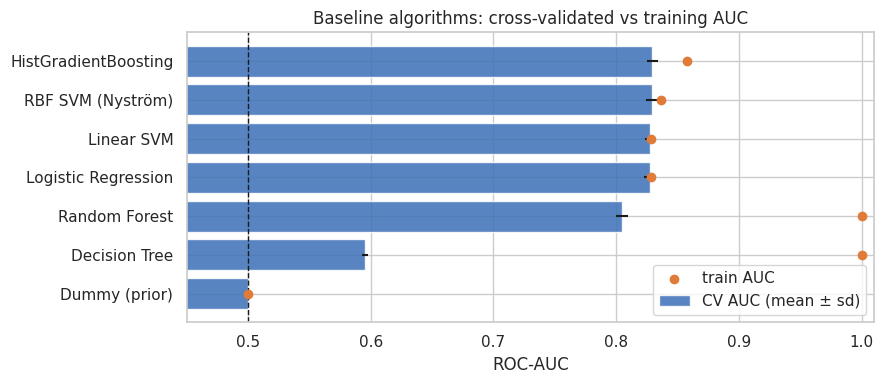

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
pdf = baseline_df.reset_index().sort_values("cv_auc_mean")
ax.barh(pdf["model"], pdf["cv_auc_mean"], xerr=pdf["cv_auc_std"], color="#3b6fb6", alpha=.85, label="CV AUC (mean ± sd)")
ax.scatter(pdf["train_auc_cv"], pdf["model"], color="#e07b39", zorder=3, label="train AUC")
ax.axvline(0.5, ls="--", color="k", lw=1)
ax.set(xlabel="ROC-AUC", title="Baseline algorithms: cross-validated vs training AUC", xlim=(0.45, 1.01))
ax.legend(loc="lower right"); plt.tight_layout(); savefig("07_baseline_comparison"); plt.show()

**Interpretation.** Four models perform almost identically: HistGradientBoosting, the RBF SVM, the Linear SVM and Logistic Regression all reach CV AUC ≈ 0.83, with very small error bars. Their training AUCs sit only slightly above (≈ 0.83–0.86), so they generalise well without overfitting. Random Forest reaches ≈ 0.80, and the Decision Tree only ≈ 0.60. Both score a perfect 1.0 on training data, the clear signature of overfitting by fully grown trees.

Because Logistic Regression matches the more flexible models, the signal is largely additive. Complex interactions add little, and the ceiling of ≈ 0.83 appears to be set by the information in self-reported features. Tuning in part 7.4 should help Random Forest most, by limiting tree growth.


### 7.2 Does feature engineering help?
Logistic Regression and Gradient Boosting are trained on three feature variants: **raw** features, **raw + engineered**, and **raw + engineered + one-hot ordinals** (which lets the linear model learn non-linear effects of age, general health, education and income).

In [14]:
variants = {
    "raw": make_preprocessor(NUMERIC_RAW, BINARY),
    "raw + engineered": make_preprocessor(NUMERIC_FULL, BINARY_FULL),
    "raw + engineered + one-hot ordinals": make_preprocessor(NUMERIC_FULL, BINARY_FULL, onehot=ORDINAL),
}
fe_rows = []
for name, model in [("Logistic Regression", LogisticRegression(max_iter=3000, random_state=SEED)),
                    ("HistGradientBoosting", HistGradientBoostingClassifier(random_state=SEED))]:
    for vname, pre in variants.items():
        p = pipe(model, pre).fit(X_train, y_train); pv = p.predict_proba(X_val)[:, 1]
        fe_rows.append({"model": name, "features": vname, "val_auc": roc_auc_score(y_val, pv), "val_pr_auc": average_precision_score(y_val, pv)})
fe_df = pd.DataFrame(fe_rows).pivot(index="model", columns="features", values="val_auc")[list(variants)]
fe_df["Δ (engineered − raw)"] = fe_df["raw + engineered"] - fe_df["raw"]
fe_df["Δ (+one-hot − raw)"] = fe_df["raw + engineered + one-hot ordinals"] - fe_df["raw"]
fe_df.to_csv(os.path.join(RES_DIR, "feature_engineering_effect.csv"))
fe_df.round(4)

features,raw,raw + engineered,raw + engineered + one-hot ordinals,Δ (engineered − raw),Δ (+one-hot − raw)
model,,,,,
HistGradientBoosting,0.8332,0.8333,0.8331,0.0001,-0.0001
Logistic Regression,0.8250,0.8275,0.8290,0.0024,0.0040


**Interpretation.** For HistGradientBoosting, feature engineering has no measurable effect (Δ ≤ ±0.0001), because trees already discover thresholds and interactions such as BMI cut-offs on their own. Logistic Regression gains modestly: +0.0024 AUC from the engineered features and +0.0040 when the ordinal columns are also one-hot encoded. Supplying non-linear structure, such as BMI classes, risk counts and per-level effects of age and general health, helps the linear model close part of the gap to boosting (0.829 vs 0.833). The gains are small but consistent, and the engineered variant is used from here on.


### 7.3 Handling class imbalance
Two standard strategies are compared on validation data. **Class weighting** (`class_weight="balanced"`) up-weights the minority class in the loss, so the model pays more attention to positives. **Threshold tuning** keeps the model unchanged but moves the decision threshold away from 0.5. Class weighting does not change the ranking of examples much, so ROC-AUC should barely move; it mainly shifts predicted probabilities upward, which raises recall at the default threshold but **damages calibration** (Brier score).

In [15]:
imb_rows = []
for name, mk in [("Logistic Regression", lambda cw: LogisticRegression(max_iter=3000, class_weight=cw, random_state=SEED)),
                 ("HistGradientBoosting", lambda cw: HistGradientBoostingClassifier(class_weight=cw, random_state=SEED))]:
    for cw in [None, "balanced"]:
        p = pipe(mk(cw)).fit(X_train, y_train); pv = p.predict_proba(X_val)[:, 1]
        imb_rows.append({"model": name, "class_weight": str(cw), "val_auc": roc_auc_score(y_val, pv),
                         "val_pr_auc": average_precision_score(y_val, pv), "brier": brier_score_loss(y_val, pv),
                         "recall@0.5": recall_score(y_val, pv >= 0.5), "precision@0.5": precision_score(y_val, pv >= 0.5, zero_division=0),
                         "mean_pred_prob": pv.mean()})
imb_df = pd.DataFrame(imb_rows).set_index(["model", "class_weight"])
imb_df.to_csv(os.path.join(RES_DIR, "imbalance_strategies.csv"))
imb_df.round(4)

val_auc  val_pr_auc   brier  recall@0.5  \
model                class_weight                                            
Logistic Regression  None           0.8275      0.4267  0.0974      0.1697   
                     balanced       0.8276      0.4237  0.1730      0.7690   
HistGradientBoosting None           0.8333      0.4407  0.0959      0.1594   
                     balanced       0.8332      0.4379  0.1730      0.8003   

                                   precision@0.5  mean_pred_prob  
model                class_weight                                 
Logistic Regression  None                 0.5535          0.1377  
                     balanced             0.3204          0.3819  
HistGradientBoosting None                 0.5884          0.1380  
                     balanced             0.3099          0.3748

**Interpretation.** Class weighting leaves ranking performance unchanged: validation AUC and PR-AUC move by less than 0.003 for both models. It only shifts where the probabilities sit. The mean predicted probability rises from ≈ 0.14, matching the true prevalence, to ≈ 0.38. Recall at the 0.5 threshold therefore jumps from ≈ 0.16 to ≈ 0.77–0.80, while precision falls from ≈ 0.55–0.59 to ≈ 0.31.

The cost is calibration. The Brier score nearly doubles, from ≈ 0.096 to 0.173, so the weighted probabilities no longer reflect real risk. Class weighting is effectively a threshold shift with distorted probabilities. The notebook keeps unweighted models and tunes the threshold on validation data instead, which achieves the same recall while keeping probabilities interpretable.



### 7.4 Hyperparameter tuning
`RandomizedSearchCV` samples configurations from distributions and scores each with 3-fold stratified ROC-AUC on the tuning sub-sample [Bergstra & Bengio, 2012]. The best configuration of each model is refitted on the full training set.

In [16]:
search_spaces = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, random_state=SEED), {
        "clf__C": stats.loguniform(1e-4, 1e2)}),
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=SEED), {
        "clf__n_estimators": stats.randint(150, 500),
        "clf__max_depth": [8, 12, 16, 24, None],
        "clf__min_samples_leaf": stats.randint(1, 80),
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=SEED, early_stopping=True), {
        "clf__learning_rate": stats.loguniform(0.01, 0.3),
        "clf__max_iter": stats.randint(100, 800),
        "clf__max_leaf_nodes": stats.randint(8, 64),
        "clf__min_samples_leaf": stats.randint(20, 300),
        "clf__l2_regularization": stats.loguniform(1e-4, 10)}),
    "Linear SVM": (CalibratedClassifierCV(LinearSVC(random_state=SEED), cv=3), {
        "clf__estimator__C": stats.loguniform(1e-4, 1e1)}),
}

searches, tuned_models, tune_rows = {}, {}, []
for name, (model, space) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(pipe(model), space, n_iter=CFG["N_ITER"], scoring="roc_auc",
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1,
                            random_state=SEED, return_train_score=True, refit=False)
    rs.fit(X_tune, y_tune)
    searches[name] = rs
    best = pipe(model).set_params(**rs.best_params_).fit(X_train, y_train)
    tuned_models[name] = best
    pv = best.predict_proba(X_val)[:, 1]
    tune_rows.append({"model": name, "best_cv_auc": rs.best_score_, "baseline_val_auc": baseline_df.loc[name, "val_auc"],
                      "tuned_val_auc": roc_auc_score(y_val, pv), "tuned_val_pr_auc": average_precision_score(y_val, pv),
                      "best_params": {k.replace("clf__", ""): (round(v, 5) if isinstance(v, float) else v) for k, v in rs.best_params_.items()},
                      "search_s": time.time() - t0})
    print(f"{name:<22} best CV AUC {rs.best_score_:.4f} → val AUC {tune_rows[-1]['tuned_val_auc']:.4f} ({time.time()-t0:.0f}s)")

tune_df = pd.DataFrame(tune_rows).set_index("model")
tune_df["Δ vs baseline"] = tune_df["tuned_val_auc"] - tune_df["baseline_val_auc"]
tune_df.to_csv(os.path.join(RES_DIR, "ml_tuning.csv"))
pd.set_option("display.max_colwidth", 200)
tune_df

Logistic Regression    best CV AUC 0.8275 → val AUC 0.8274 (12s)
Random Forest          best CV AUC 0.8268 → val AUC 0.8298 (748s)
HistGradientBoosting   best CV AUC 0.8310 → val AUC 0.8330 (181s)
Linear SVM             best CV AUC 0.8279 → val AUC 0.8274 (27s)


,best_cv_auc,baseline_val_auc,tuned_val_auc,tuned_val_pr_auc,best_params,search_s,Δ vs baseline
model,,,,,,,
Logistic Regression,0.827491,0.827476,0.827427,0.426722,{'C': 0.14078},12.438224,-4.878470e-05
Random Forest,0.826838,0.803700,0.829842,0.435290,"{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 30, 'n_estimators': 443}",747.969359,2.614193e-02
HistGradientBoosting,0.830987,0.833292,0.833034,0.438127,"{'l2_regularization': 3.52048, 'learning_rate': 0.02411, 'max_iter': 487, 'max_leaf_nodes': 9, 'min_samples_leaf': 73}",181.471586,-2.581253e-04
Linear SVM,0.827904,0.827446,0.827445,0.422484,{'estimator__C': 0.45706},26.674762,-4.607220e-07


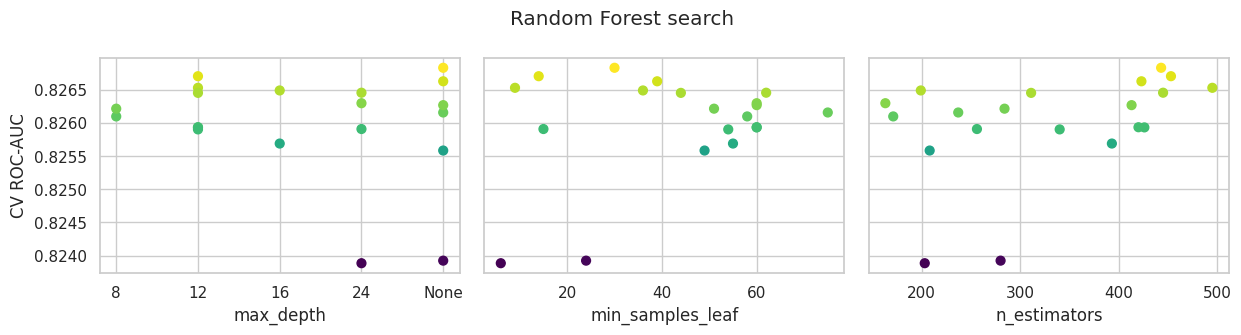

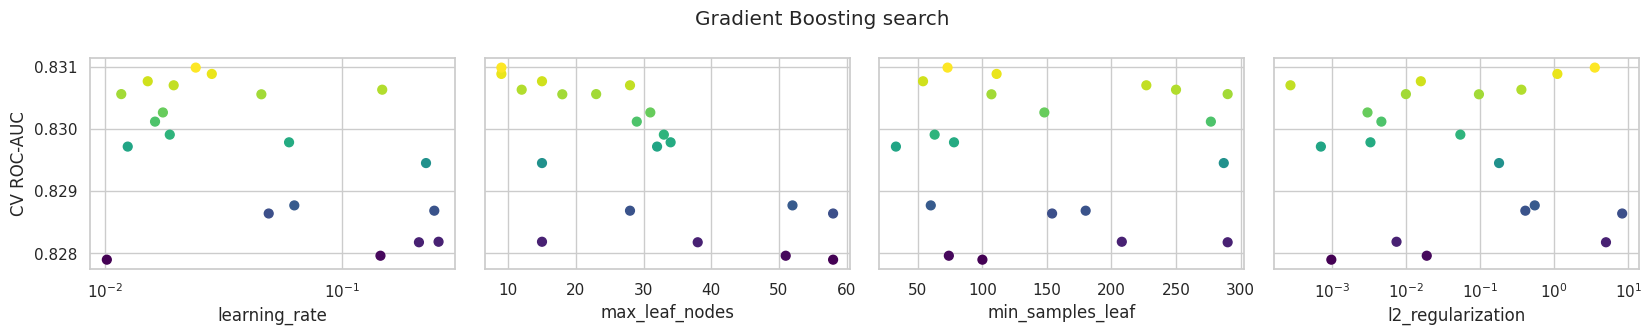

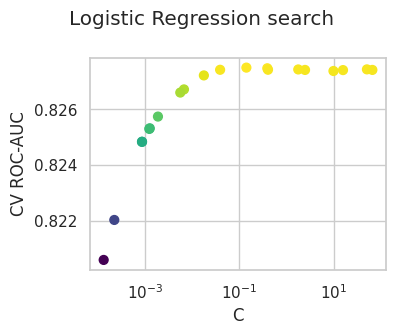

In [17]:
def plot_search(rs, params, title, fname):
    res = pd.DataFrame(rs.cv_results_)
    fig, axes = plt.subplots(1, len(params), figsize=(4.2 * len(params), 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, p in zip(axes, params):
        x = res[f"param_{p}"]
        num = pd.to_numeric(x, errors="coerce")
        if num.notna().all():
            x_plot = num
        else:  # mixed values such as max_depth=None → plot as ordered categories
            x_plot = x.astype(object).where(x.notna(), "None").astype(str)
            cats = sorted(x_plot.unique(), key=lambda v: (not v.replace(".", "").isdigit(), float(v) if v.replace(".", "").isdigit() else 0, v))
            x_plot = pd.Categorical(x_plot, categories=cats, ordered=True).codes
            ax.set_xticks(range(len(cats))); ax.set_xticklabels(cats)
        ax.scatter(x_plot, res["mean_test_score"], c=res["mean_test_score"], cmap="viridis", s=40)
        ax.set(xlabel=p.replace("clf__", "").replace("estimator__", ""))
        if p in ("clf__C", "clf__learning_rate", "clf__l2_regularization", "clf__estimator__C"):
            ax.set_xscale("log")
    axes[0].set_ylabel("CV ROC-AUC"); fig.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

plot_search(searches["Random Forest"], ["clf__max_depth", "clf__min_samples_leaf", "clf__n_estimators"], "Random Forest search", "07_search_rf")
plot_search(searches["HistGradientBoosting"], ["clf__learning_rate", "clf__max_leaf_nodes", "clf__min_samples_leaf", "clf__l2_regularization"], "Gradient Boosting search", "07_search_hgb")
plot_search(searches["Logistic Regression"], ["clf__C"], "Logistic Regression search", "07_search_lr")

📝 **Interpretation.** All three searches show narrow performance ranges, so the models are robust to their hyperparameters.

Random Forest varies only between ≈ 0.824 and 0.827. The two weakest configurations combine deep trees with small leaves, while depth and tree count otherwise matter little.

Gradient Boosting spans ≈ 0.828–0.831. It performs best with a low learning rate (≈ 0.02–0.03) and few leaf nodes (≈ 9–15), and degrades with higher learning rates and larger trees.

Logistic Regression plateaus at ≈ 0.8275 for any C above about 0.01. Only very strong regularisation (C < 10⁻³) hurts, so regularisation strength barely matters with this many rows.

Tuning made no meaningful difference to Logistic Regression, HistGradientBoosting or the Linear SVM (Δ within ±0.0003). Only Random Forest gained substantially (+0.026 AUC, from 0.804 to 0.830), because raising min_samples_leaf to 30 curbed the overfitting seen in part 7.1. This confirms that the ≈ 0.83 ceiling is set by the information in the features, not by model configuration.

### 7.5 Learning curves
Learning curves plot training and cross-validated AUC as training size grows. Converging curves at a modest value indicate **high bias** (more data will not help, richer features would). A persistent gap indicates **high variance** (more data or stronger regularisation would help).

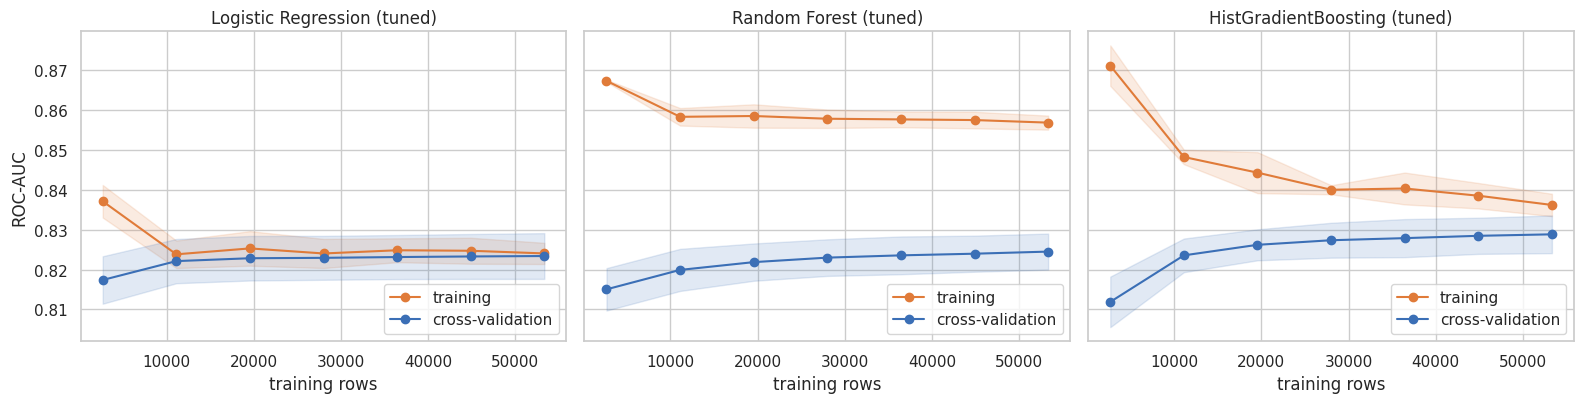

In [18]:
lc_idx = rng.choice(len(X_train), size=min(CFG["LC_SAMPLE"], len(X_train)), replace=False)
X_lc, y_lc = X_train.iloc[lc_idx], y_train[lc_idx]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, name in zip(axes, ["Logistic Regression", "Random Forest", "HistGradientBoosting"]):
    sizes, tr, te = learning_curve(clone(tuned_models[name]), X_lc, y_lc, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                                   scoring="roc_auc", train_sizes=np.linspace(0.05, 1.0, 7), n_jobs=-1)
    for scores, lab, col in [(tr, "training", "#e07b39"), (te, "cross-validation", "#3b6fb6")]:
        m, s = scores.mean(1), scores.std(1)
        ax.plot(sizes, m, "o-", color=col, label=lab); ax.fill_between(sizes, m - s, m + s, color=col, alpha=.15)
    ax.set(title=f"{name} (tuned)", xlabel="training rows"); ax.legend(loc="lower right")
axes[0].set_ylabel("ROC-AUC")
plt.tight_layout(); savefig("07_learning_curves_ml"); plt.show()

**Interpretation.** Logistic Regression is bias-limited: its curves converge by about 10,000 rows and stay level at ≈ 0.823–0.825, so more data does not help. Random Forest keeps a persistent gap (training ≈ 0.857 against validation ≈ 0.825), indicating some remaining variance. HistGradientBoosting’s curves narrow steadily as data grows (training falls to ≈ 0.836, validation rises to ≈ 0.829), so it benefits slightly from more rows but is approaching convergence. All three validation curves flatten at ≈ 0.82–0.83 well before the full sample is used. The limit is the information content of self-reported indicators, not the amount of data or model capacity.

## 8. Deep learning (TensorFlow / Keras)

Two architectures are implemented, both fed through `tf.data` pipelines.

**Model A: Sequential MLP** on the same scaled feature matrix the scikit-learn models use, so the comparison isolates the learner.

**Model B: Functional wide-and-deep network with entity embeddings.** The four ordinal variables (general health, age band, education, income) and `bmi_class` each get their own input and a learned embedding [Guo & Berkhahn, 2016], which lets the network learn non-linear, non-monotonic effects of each level. These are concatenated with the scaled continuous features and the binary indicators, then passed through a *deep* branch (stacked dense layers) and a *wide* linear branch, whose logits are summed [Cheng et al., 2016].

All networks use early stopping on validation AUC (restoring the best weights) and ReduceLROnPlateau. Because of the class imbalance, three **loss strategies** are compared: plain binary cross-entropy, class-weighted cross-entropy, and **focal loss** [Lin et al., 2017], which down-weights easy examples so training concentrates on hard, often minority-class, cases.

### 8.1 `tf.data` input pipelines

In [19]:
pre_dl = make_preprocessor().fit(X_train)
Xtr_dl, Xva_dl, Xte_dl = (pre_dl.transform(X).astype("float32") for X in (X_train, X_val, X_test))
ytr_dl, yva_dl, yte_dl = (a.astype("float32") for a in (y_train, y_val, y_test))
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X, y, batch_size, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(y), 100_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

EMB_COLS = ORDINAL + ["bmi_class"]
DENSE_NUM = CONTINUOUS + ["cardio_risk_count", "lifestyle_score", "age_x_bmi"]
DENSE_BIN = BINARY_FULL
ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(X_train[EMB_COLS])
num_scaler = StandardScaler().fit(X_train[DENSE_NUM])
CARD = {c: len(cats) + 1 for c, cats in zip(EMB_COLS, ord_enc.categories_)}

def to_dict(X):
    codes = (ord_enc.transform(X[EMB_COLS]) + 1).astype("int32")
    d = {c: codes[:, i:i+1] for i, c in enumerate(EMB_COLS)}
    d["numeric"] = num_scaler.transform(X[DENSE_NUM]).astype("float32")
    d["binary"] = X[DENSE_BIN].values.astype("float32")
    return d

Dtr, Dva, Dte = to_dict(X_train), to_dict(X_val), to_dict(X_test)

def make_dict_ds(D, y, batch_size, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((D, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(y), 100_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

xb, yb = next(iter(make_ds(Xtr_dl, ytr_dl, 4, True)))
print("MLP batch:", xb.shape, yb.shape)
db, _ = next(iter(make_dict_ds(Dtr, ytr_dl, 4, True)))
print("Embedding-net inputs:", {k: tuple(v.shape) for k, v in db.items()})
print("Embedding cardinalities:", CARD)

MLP batch: (4, 28) (4,)
Embedding-net inputs: {'GenHlth': (4, 1), 'Age': (4, 1), 'Education': (4, 1), 'Income': (4, 1), 'bmi_class': (4, 1), 'numeric': (4, 6), 'binary': (4, 17)}
Embedding cardinalities: {'GenHlth': 6, 'Age': 14, 'Education': 7, 'Income': 9, 'bmi_class': 7}


### 8.2 Model builders and training loop

In [20]:
neg, pos = np.bincount(y_train)
CLASS_WEIGHT = {0: len(y_train) / (2 * neg), 1: len(y_train) / (2 * pos)}

def get_loss(name):
    if name == "focal":
        return keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.75, gamma=2.0)
    return keras.losses.BinaryCrossentropy()

def get_optimizer(name, lr):
    return {"adam": keras.optimizers.Adam(lr), "rmsprop": keras.optimizers.RMSprop(lr),
            "sgd": keras.optimizers.SGD(lr, momentum=0.9, nesterov=True)}[name]

METRICS = lambda: [keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc")]

def build_mlp(input_dim, units=(128, 64), dropout=0.3, l2=1e-4, batch_norm=True, lr=1e-3, optimizer="adam", loss="bce"):
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(input_dim,)))
    for u in units:
        model.add(layers.Dense(u, use_bias=not batch_norm, kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if batch_norm: model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout: model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=get_optimizer(optimizer, lr), loss=get_loss(loss), metrics=METRICS())
    return model

def build_wide_deep(emb_scale=1.0, units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3):
    inputs, parts = {}, []
    for c in EMB_COLS:
        inp = keras.Input(shape=(1,), dtype="int32", name=c)
        dim = max(2, int(round(emb_scale * min(8, (CARD[c] + 1) // 2))))
        parts.append(layers.Flatten()(layers.Embedding(CARD[c], dim, name=f"emb_{c}")(inp))); inputs[c] = inp
    inputs["numeric"] = keras.Input(shape=(len(DENSE_NUM),), name="numeric")
    inputs["binary"] = keras.Input(shape=(len(DENSE_BIN),), name="binary")
    x = layers.Concatenate(name="concat")(parts + [inputs["numeric"], inputs["binary"]])
    wide = layers.Dense(1, name="wide_logit")(x)
    h = x
    for i, u in enumerate(units):
        h = layers.Dense(u, activation="relu", kernel_regularizer=regularizers.l2(l2), name=f"deep_{i}")(h)
        h = layers.Dropout(dropout)(h)
    deep = layers.Dense(1, name="deep_logit")(h)
    out = layers.Activation("sigmoid", name="prob")(layers.Add()([wide, deep]))
    model = keras.Model(inputs, out, name="wide_deep_embeddings")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=METRICS())
    return model

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=2, min_lr=1e-5)]

def train(model, ds_tr, ds_va, class_weight=None):
    t0 = time.time()
    hist = model.fit(ds_tr, validation_data=ds_va, epochs=CFG["EPOCHS"], callbacks=callbacks(),
                     class_weight=class_weight, verbose=0)
    return pd.DataFrame(hist.history), time.time() - t0

print("Class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})
build_mlp(Xtr_dl.shape[1]).summary()

Class weights: {0: np.float64(0.581), 1: np.float64(3.589)}


Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,609 (49.25 KB)

 Trainable params: 12,225 (47.75 KB)

 Non-trainable params: 384 (1.50 KB)

### 8.3 Experiment series for the Sequential MLP
Each experiment changes one factor from a plain baseline, so effects can be attributed. The series covers **regularisation** (none → dropout → dropout + batch normalisation + L2), **capacity** (wider, deeper), **imbalance-aware losses** (class-weighted BCE, focal loss), **optimiser** (Adam, RMSprop, SGD with Nesterov momentum), **learning rate**, and **batch size**.

In [21]:
mlp_experiments = [
    dict(name="M1 plain (no reg.)",     units=(64, 32),       dropout=0.0, l2=0.0,  batch_norm=False, lr=1e-3, optimizer="adam",    loss="bce",   cw=False, batch=512),
    dict(name="M2 + dropout 0.3",       units=(64, 32),       dropout=0.3, l2=0.0,  batch_norm=False, lr=1e-3, optimizer="adam",    loss="bce",   cw=False, batch=512),
    dict(name="M3 + BN + L2",           units=(64, 32),       dropout=0.3, l2=1e-4, batch_norm=True,  lr=1e-3, optimizer="adam",    loss="bce",   cw=False, batch=512),
    dict(name="M4 wider 256-128",       units=(256, 128),     dropout=0.3, l2=1e-4, batch_norm=True,  lr=1e-3, optimizer="adam",    loss="bce",   cw=False, batch=512),
    dict(name="M5 deeper 256-128-64",   units=(256, 128, 64), dropout=0.4, l2=1e-4, batch_norm=True,  lr=1e-3, optimizer="adam",    loss="bce",   cw=False, batch=512),
    dict(name="M6 class-weighted BCE",  units=(128, 64),      dropout=0.3, l2=1e-4, batch_norm=True,  lr=1e-3, optimizer="adam",    loss="bce",   cw=True,  batch=512),
    dict(name="M7 focal loss",          units=(128, 64),      dropout=0.3, l2=1e-4, batch_norm=True,  lr=1e-3, optimizer="adam",    loss="focal", cw=False, batch=512),
    dict(name="M8 RMSprop",             units=(128, 64),      dropout=0.3, l2=1e-4, batch_norm=True,  lr=1e-3, optimizer="rmsprop", loss="bce",   cw=False, batch=512),
    dict(name="M9 SGD+Nesterov",        units=(128, 64),      dropout=0.3, l2=1e-4, batch_norm=True,  lr=1e-2, optimizer="sgd",     loss="bce",   cw=False, batch=512),
    dict(name="M10 low LR 3e-4",        units=(128, 64),      dropout=0.3, l2=1e-4, batch_norm=True,  lr=3e-4, optimizer="adam",    loss="bce",   cw=False, batch=512),
    dict(name="M11 large batch 2048",   units=(128, 64),      dropout=0.3, l2=1e-4, batch_norm=True,  lr=2e-3, optimizer="adam",    loss="bce",   cw=False, batch=2048),
]

mlp_results, mlp_histories, mlp_models = [], {}, {}
for cfg in mlp_experiments:
    tf.keras.utils.set_random_seed(SEED)
    params = {k: v for k, v in cfg.items() if k not in ("name", "batch", "cw")}
    m = build_mlp(Xtr_dl.shape[1], **params)
    h, secs = train(m, make_ds(Xtr_dl, ytr_dl, cfg["batch"], True), make_ds(Xva_dl, yva_dl, 4096, False),
                    class_weight=CLASS_WEIGHT if cfg["cw"] else None)
    b = int(h["val_auc"].idxmax())
    mlp_results.append({"experiment": cfg["name"], "params": m.count_params(), "best_epoch": b + 1, "epochs_run": len(h),
                        "train_auc@best": h.loc[b, "auc"], "val_auc@best": h.loc[b, "val_auc"],
                        "val_pr_auc@best": h.loc[b, "val_pr_auc"], "gap": h.loc[b, "auc"] - h.loc[b, "val_auc"], "seconds": secs})
    mlp_histories[cfg["name"]], mlp_models[cfg["name"]] = h, m
    print(f"{cfg['name']:<24} val AUC {mlp_results[-1]['val_auc@best']:.4f} | PR-AUC {mlp_results[-1]['val_pr_auc@best']:.4f} (epoch {b+1}/{len(h)}, {secs:.0f}s)")

mlp_df = pd.DataFrame(mlp_results).set_index("experiment")
mlp_df.to_csv(os.path.join(RES_DIR, "dl_mlp_experiments.csv"))
mlp_df.round(4)

M1 plain (no reg.)       val AUC 0.8317 | PR-AUC 0.4396 (epoch 6/11, 17s)
M2 + dropout 0.3         val AUC 0.8329 | PR-AUC 0.4395 (epoch 23/28, 47s)
M3 + BN + L2             val AUC 0.8332 | PR-AUC 0.4409 (epoch 23/28, 55s)
M4 wider 256-128         val AUC 0.8326 | PR-AUC 0.4409 (epoch 19/24, 96s)
M5 deeper 256-128-64     val AUC 0.8331 | PR-AUC 0.4415 (epoch 31/36, 174s)
M6 class-weighted BCE    val AUC 0.8326 | PR-AUC 0.4389 (epoch 17/22, 64s)
M7 focal loss            val AUC 0.8331 | PR-AUC 0.4414 (epoch 27/32, 84s)
M8 RMSprop               val AUC 0.8332 | PR-AUC 0.4416 (epoch 22/27, 74s)
M9 SGD+Nesterov          val AUC 0.8307 | PR-AUC 0.4327 (epoch 38/40, 106s)
M10 low LR 3e-4          val AUC 0.8316 | PR-AUC 0.4360 (epoch 34/39, 104s)
M11 large batch 2048     val AUC 0.8324 | PR-AUC 0.4382 (epoch 19/24, 49s)


,params,best_epoch,epochs_run,train_auc@best,val_auc@best,val_pr_auc@best,gap,seconds
experiment,,,,,,,,
M1 plain (no reg.),3969,6,11,0.8308,0.8317,0.4396,-0.0009,17.4583
M2 + dropout 0.3,3969,23,28,0.8284,0.8329,0.4395,-0.0045,47.4682
M3 + BN + L2,4257,23,28,0.8276,0.8332,0.4409,-0.0055,54.5423
M4 wider 256-128,41601,19,24,0.8316,0.8326,0.4409,-0.0010,95.5612
M5 deeper 256-128-64,49985,31,36,0.8291,0.8331,0.4415,-0.0040,174.0655
M6 class-weighted BCE,12609,17,22,0.8294,0.8326,0.4389,-0.0032,63.6073
M7 focal loss,12609,27,32,0.8301,0.8331,0.4414,-0.0030,83.6777
M8 RMSprop,12609,22,27,0.8296,0.8332,0.4416,-0.0036,73.9012
M9 SGD+Nesterov,12609,38,40,0.8241,0.8307,0.4327,-0.0067,105.6849


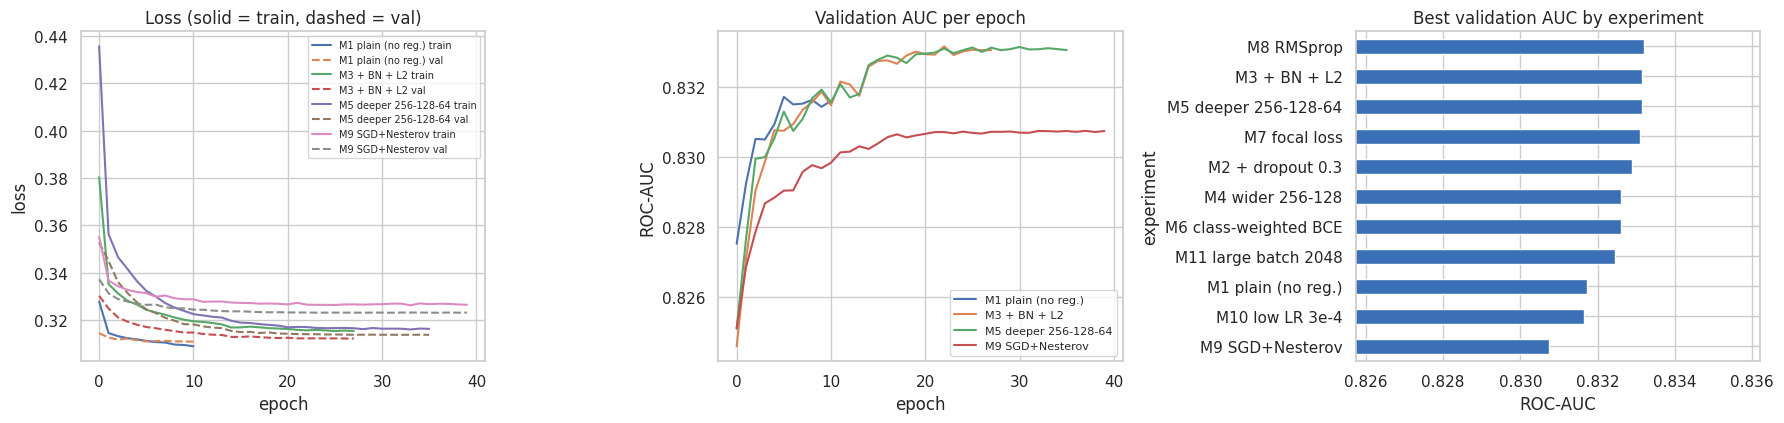

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for name in ["M1 plain (no reg.)", "M3 + BN + L2", "M5 deeper 256-128-64", "M9 SGD+Nesterov"]:
    h = mlp_histories[name]
    axes[0].plot(h["loss"], label=f"{name} train"); axes[0].plot(h["val_loss"], "--", label=f"{name} val")
    axes[1].plot(h["val_auc"], label=name)
axes[0].set(title="Loss (solid = train, dashed = val)", xlabel="epoch", ylabel="loss")
axes[1].set(title="Validation AUC per epoch", xlabel="epoch", ylabel="ROC-AUC")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=8)
mlp_df["val_auc@best"].sort_values().plot.barh(ax=axes[2], color="#3b6fb6")
axes[2].set(title="Best validation AUC by experiment", xlabel="ROC-AUC",
            xlim=(mlp_df["val_auc@best"].min() - 0.005, mlp_df["val_auc@best"].max() + 0.003))
plt.tight_layout(); savefig("08_mlp_experiments"); plt.show()

**Interpretation.** All eleven configurations fall within a very narrow band of validation AUC (0.8307–0.8332). Validation loss tracks training loss closely, and every train–validation gap is near zero or slightly negative, so no network overfits. Training metrics sit slightly below validation because dropout and batch normalisation are active during training.

Regularisation, extra capacity and the choice of loss make no practical difference. Wider and deeper models with 42k–50k parameters match the 4k-parameter baseline, and class weighting (M6) and focal loss (M7) leave AUC and PR-AUC unchanged. SGD with Nesterov momentum (M9) and the low learning rate (M10) converge more slowly and finish slightly lower, around 0.831.

The best MLPs (≈ 0.833) match tuned HistGradientBoosting (0.833) on the same validation set. This confirms that deep learning reaches, but cannot exceed, the ceiling set by the features.


### 8.4 Experiment series for the Functional wide-and-deep network

In [23]:
wd_experiments = [
    dict(name="W1 emb×1, drop 0.3", emb_scale=1.0, units=(128, 64),  dropout=0.3, l2=1e-4, lr=1e-3),
    dict(name="W2 emb×2, drop 0.3", emb_scale=2.0, units=(128, 64),  dropout=0.3, l2=1e-4, lr=1e-3),
    dict(name="W3 emb×1, drop 0.5", emb_scale=1.0, units=(256, 128), dropout=0.5, l2=1e-3, lr=1e-3),
]
wd_results, wd_histories, wd_models = [], {}, {}
for cfg in wd_experiments:
    tf.keras.utils.set_random_seed(SEED)
    m = build_wide_deep(**{k: v for k, v in cfg.items() if k != "name"})
    h, secs = train(m, make_dict_ds(Dtr, ytr_dl, 512, True), make_dict_ds(Dva, yva_dl, 4096, False))
    b = int(h["val_auc"].idxmax())
    wd_results.append({"experiment": cfg["name"], "params": m.count_params(), "best_epoch": b + 1, "epochs_run": len(h),
                       "train_auc@best": h.loc[b, "auc"], "val_auc@best": h.loc[b, "val_auc"],
                       "val_pr_auc@best": h.loc[b, "val_pr_auc"], "gap": h.loc[b, "auc"] - h.loc[b, "val_auc"], "seconds": secs})
    wd_histories[cfg["name"]], wd_models[cfg["name"]] = h, m
    print(f"{cfg['name']:<22} val AUC {wd_results[-1]['val_auc@best']:.4f} (epoch {b+1}/{len(h)}, {secs:.0f}s)")
wd_df = pd.DataFrame(wd_results).set_index("experiment")
wd_df.to_csv(os.path.join(RES_DIR, "dl_wide_deep_experiments.csv"))
wd_models[wd_df["val_auc@best"].idxmax()].summary()
wd_df.round(4)

W1 emb×1, drop 0.3     val AUC 0.8331 (epoch 20/25, 90s)
W2 emb×2, drop 0.3     val AUC 0.8335 (epoch 27/32, 121s)
W3 emb×1, drop 0.5     val AUC 0.8311 (epoch 26/31, 144s)


Model: "wide_deep_embeddings"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ GenHlth             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Age (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Education           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Income (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bmi_class           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_GenHlth         │ (None, 1, 6)      │         36 │ GenHlth[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_Age (Embedding) │ (None, 1, 14)     │        196 │ Age[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_Education       │ (None, 1, 8)      │         56 │ Education[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_Income          │ (None, 1, 10)     │         90 │ Income[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_bmi_class       │ (None, 1, 8)      │         56 │ bmi_class[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 6)         │          0 │ emb_GenHlth[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 14)        │          0 │ emb_Age[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 8)         │          0 │ emb_Education[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 10)        │          0 │ emb_Income[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 8)         │          0 │ emb_bmi_class[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ binary (InputLayer) │ (None, 17)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, 69)        │          0 │ flatten_5[0][0],  │
│ (Concatenate)       │                   │            │ flatten_6[0][0],  │
│                     │                   │            │ flatten_7[0][0],  │
│                     │                   │            │ flatten_8[0][0],  │
│                     │                   │            │ flatten_9[0][0],  │
│                     │                   │            │ numeric[0][0],    │
│                     │                   │            │ binary[0][0]    

 Total params: 53,357 (208.43 KB)

 Trainable params: 17,785 (69.47 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 35,572 (138.96 KB)

,params,best_epoch,epochs_run,train_auc@best,val_auc@best,val_pr_auc@best,gap,seconds
experiment,,,,,,,,
"W1 emb×1, drop 0.3",14601,20,25,0.8322,0.8331,0.4415,-0.0010,89.9557
"W2 emb×2, drop 0.3",17785,27,32,0.8332,0.8335,0.4418,-0.0003,121.0645
"W3 emb×1, drop 0.5",45321,26,31,0.8284,0.8311,0.4358,-0.0027,144.3205


Best MLP: M8 RMSprop | Best wide-and-deep: W2 emb×2, drop 0.3


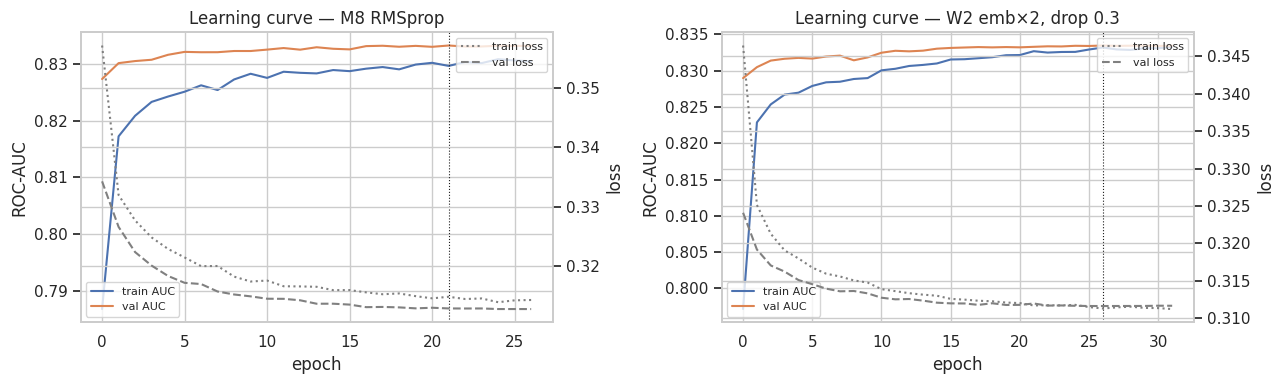

In [24]:
best_mlp_name, best_wd_name = mlp_df["val_auc@best"].idxmax(), wd_df["val_auc@best"].idxmax()
best_mlp, best_wd = mlp_models[best_mlp_name], wd_models[best_wd_name]
print("Best MLP:", best_mlp_name, "| Best wide-and-deep:", best_wd_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, h) in zip(axes, [(best_mlp_name, mlp_histories[best_mlp_name]), (best_wd_name, wd_histories[best_wd_name])]):
    ax.plot(h["auc"], label="train AUC"); ax.plot(h["val_auc"], label="val AUC")
    ax2 = ax.twinx(); ax2.plot(h["loss"], ":", color="gray", label="train loss"); ax2.plot(h["val_loss"], "--", color="gray", label="val loss")
    ax.axvline(h["val_auc"].idxmax(), color="k", lw=.8, ls=":")
    ax.set(title=f"Learning curve — {name}", xlabel="epoch", ylabel="ROC-AUC"); ax2.set_ylabel("loss")
    ax.legend(loc="lower left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout(); savefig("08_dl_learning_curves_best"); plt.show()
best_mlp.save(os.path.join(MODEL_DIR, "best_mlp.keras")); best_wd.save(os.path.join(MODEL_DIR, "best_wide_deep.keras"))

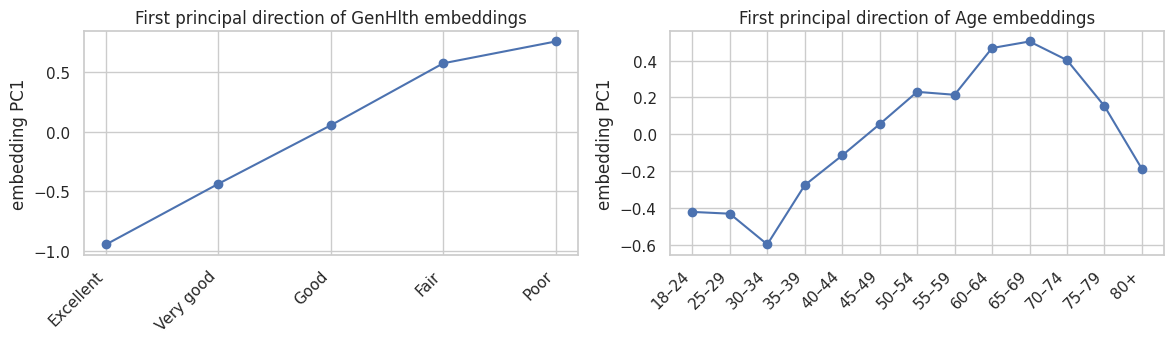

In [25]:
# What did the embeddings learn? Project each level of General Health and Age onto the wide-and-deep logit direction
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col, labels in [(axes[0], "GenHlth", ["Excellent", "Very good", "Good", "Fair", "Poor"]),
                        (axes[1], "Age", ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54", "55–59", "60–64", "65–69", "70–74", "75–79", "80+"])]:
    W = best_wd.get_layer(f"emb_{col}").get_weights()[0][1:]          # drop the 'unknown' row
    W = W - W.mean(0)
    u, s, vt = np.linalg.svd(W, full_matrices=False)
    comp = W @ vt[0]
    if np.corrcoef(comp, np.arange(len(comp)))[0, 1] < 0: comp = -comp
    ax.plot(range(len(comp)), comp, "o-"); ax.set_xticks(range(len(comp))); ax.set_xticklabels(labels[:len(comp)], rotation=45, ha="right")
    ax.set(title=f"First principal direction of {col} embeddings", ylabel="embedding PC1")
plt.tight_layout(); savefig("08_embedding_structure"); plt.show()

**Interpretation.** The best MLP (M8, RMSprop) and the best wide-and-deep network (W2, doubled embeddings, dropout 0.3) both converge smoothly. Training and validation loss fall together and level off without diverging, so neither overfits. Validation AUC stays slightly above training AUC throughout because dropout is active during training. Early stopping restored epochs ≈ 21 and ≈ 26, with both networks plateauing at a validation AUC of ≈ 0.833.

The embedding plots show the network learned meaningful structure without being told the order of any category. General-health embeddings form a perfectly monotonic line from “Excellent” to “Poor”, matching clinical intuition. Age embeddings rise steadily to a peak at 65–69 and then decline through 80+. This mirrors the prevalence pattern in §4.2 and may reflect survivor effects in the oldest group. A linear ordinal encoding could not capture this rise-and-fall shape, but the embeddings learn it directly, which is the main advantage of the wide-and-deep architecture.

## 9. Final evaluation on the held-out test set

For a screening tool, the decision threshold matters as much as the model. Two thresholds are chosen on the **validation** set and applied unchanged to the test set. The **F1-optimal** threshold balances precision and recall. The **screening** threshold is the highest threshold that still achieves **recall ≥ 0.80**, reflecting a use case where missing a case is costlier than a false alarm. ROC-AUC is reported with a 95% bootstrap confidence interval; the Brier score measures calibration.

In [26]:
final_models = {
    "Dummy (prior)":         ("sk", fitted_baselines["Dummy (prior)"]),
    "Logistic Regression":   ("sk", tuned_models["Logistic Regression"]),
    "Decision Tree":         ("sk", fitted_baselines["Decision Tree"]),
    "Random Forest":         ("sk", tuned_models["Random Forest"]),
    "HistGradientBoosting":  ("sk", tuned_models["HistGradientBoosting"]),
    "Linear SVM":            ("sk", tuned_models["Linear SVM"]),
    "RBF SVM (Nyström)":     ("sk", fitted_baselines["RBF SVM (Nyström)"]),
    "MLP (Sequential)":      ("mlp", best_mlp),
    "Wide & Deep (Functional)": ("wd", best_wd),
}

def predict(kind, m, split):
    if kind == "sk":  return m.predict_proba({"val": X_val, "test": X_test}[split])[:, 1]
    if kind == "mlp": return m.predict(make_ds({"val": Xva_dl, "test": Xte_dl}[split], {"val": yva_dl, "test": yte_dl}[split], 4096, False), verbose=0).ravel()
    return m.predict(make_dict_ds({"val": Dva, "test": Dte}[split], {"val": yva_dl, "test": yte_dl}[split], 4096, False), verbose=0).ravel()

def f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])]) if len(thr) else 0.5

def recall_threshold(y, p, target=0.80):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else 0.0

def bootstrap_auc(y, p, n=CFG["N_BOOT"]):
    r = np.random.default_rng(SEED); out = []
    for _ in range(n):
        b = r.integers(0, len(y), len(y))
        if y[b].min() != y[b].max(): out.append(roc_auc_score(y[b], p[b]))
    return np.percentile(out, [2.5, 97.5])

def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
            "specificity": tn / (tn + fp) if (tn + fp) else 0, "f1": f1_score(y, yhat), "bal_acc": balanced_accuracy_score(y, yhat)}

probs_val, probs_test, rows = {}, {}, []
for name, (kind, m) in final_models.items():
    pv, pt = predict(kind, m, "val"), predict(kind, m, "test")
    probs_val[name], probs_test[name] = pv, pt
    thr_f1, thr_scr = f1_threshold(y_val, pv), recall_threshold(y_val, pv)
    lo, hi = bootstrap_auc(y_test, pt)
    row = {"model": name, "paradigm": "ML" if kind == "sk" else "DL", "roc_auc": roc_auc_score(y_test, pt),
           "auc_95ci": f"[{lo:.4f}, {hi:.4f}]", "pr_auc": average_precision_score(y_test, pt), "brier": brier_score_loss(y_test, pt),
           "thr_f1": thr_f1}
    row.update({f"{k}@f1thr": v for k, v in metrics(y_test, pt, thr_f1).items()})
    row["thr_screen"] = thr_scr
    row.update({f"{k}@screen": v for k, v in metrics(y_test, pt, thr_scr).items() if k in ("precision", "recall", "specificity")})
    rows.append(row)

results_df = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
results_df.to_csv(os.path.join(RES_DIR, "final_test_results.csv"))
results_df.round(4)

,paradigm,roc_auc,auc_95ci,pr_auc,brier,thr_f1,precision@f1thr,recall@f1thr,specificity@f1thr,f1@f1thr,bal_acc@f1thr,thr_screen,precision@screen,recall@screen,specificity@screen
model,,,,,,,,,,,,,,,
Wide & Deep (Functional),DL,0.8285,"[0.8231, 0.8340]",0.4211,0.0974,0.2421,0.3866,0.5939,0.8474,0.4683,0.7207,0.1413,0.3079,0.7988,0.7093
MLP (Sequential),DL,0.8284,"[0.8230, 0.8338]",0.4203,0.0973,0.2333,0.3720,0.6381,0.8256,0.4700,0.7318,0.1481,0.3055,0.8012,0.7051
HistGradientBoosting,ML,0.8271,"[0.8217, 0.8325]",0.4184,0.0977,0.2370,0.3848,0.6003,0.8446,0.4690,0.7225,0.1374,0.3057,0.7946,0.7078
RBF SVM (Nyström),ML,0.8252,"[0.8197, 0.8309]",0.4184,0.0996,0.2004,0.3973,0.5702,0.8600,0.4683,0.7151,0.1043,0.3062,0.7980,0.7073
Random Forest,ML,0.8237,"[0.8181, 0.8292]",0.4154,0.0981,0.2426,0.3853,0.5830,0.8494,0.4639,0.7162,0.1430,0.2998,0.8008,0.6972
Logistic Regression,ML,0.8213,"[0.8158, 0.8268]",0.4026,0.0994,0.2006,0.3625,0.6298,0.8207,0.4601,0.7252,0.1254,0.3002,0.7944,0.7002
Linear SVM,ML,0.8212,"[0.8156, 0.8265]",0.4001,0.0999,0.1887,0.3618,0.6345,0.8188,0.4608,0.7266,0.1215,0.3014,0.7923,0.7027
Decision Tree,ML,0.5977,"[0.5907, 0.6042]",0.1897,0.2047,0.6667,0.2904,0.3229,0.8722,0.3058,0.5976,0.0000,0.1393,1.0000,0.0000
Dummy (prior),ML,0.5000,"[0.5000, 0.5000]",0.1393,0.1199,0.1393,0.1393,1.0000,0.0000,0.2446,0.5000,0.1393,0.1393,1.0000,0.0000


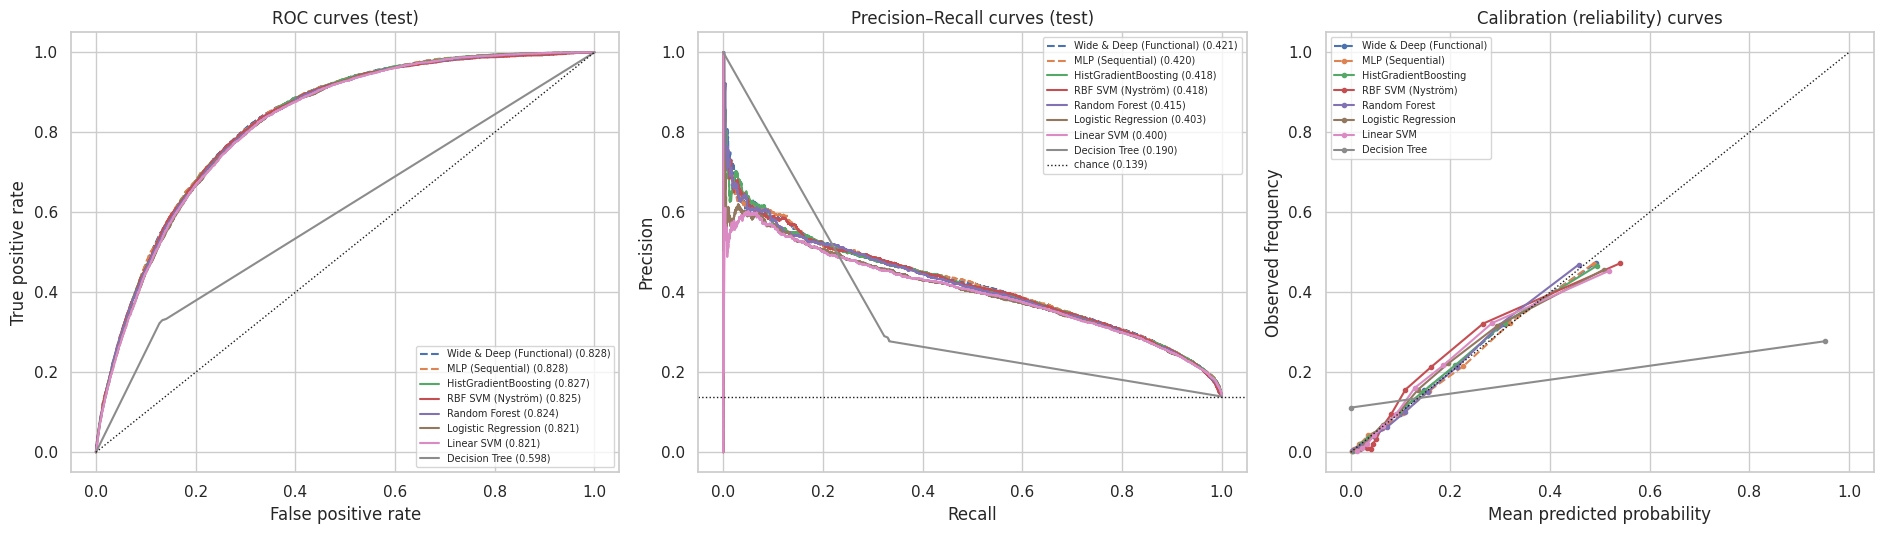

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for name in results_df.index:
    if name == "Dummy (prior)": continue
    ls = "--" if results_df.loc[name, "paradigm"] == "DL" else "-"
    fpr, tpr, _ = roc_curve(y_test, probs_test[name]); axes[0].plot(fpr, tpr, ls, label=f"{name} ({results_df.loc[name,'roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, probs_test[name]); axes[1].plot(rc, pr, ls, label=f"{name} ({results_df.loc[name,'pr_auc']:.3f})")
    fr, mp = calibration_curve(y_test, probs_test[name], n_bins=10, strategy="quantile"); axes[2].plot(mp, fr, ls + "o", ms=3, label=name)
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"chance ({y_test.mean():.3f})")
axes[1].set(title="Precision–Recall curves (test)", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], "k:", lw=1); axes[2].set(title="Calibration (reliability) curves", xlabel="Mean predicted probability", ylabel="Observed frequency")
axes[0].legend(fontsize=7, loc="lower right"); axes[1].legend(fontsize=7, loc="upper right"); axes[2].legend(fontsize=7, loc="upper left")
plt.tight_layout(); savefig("09_roc_pr_calibration"); plt.show()

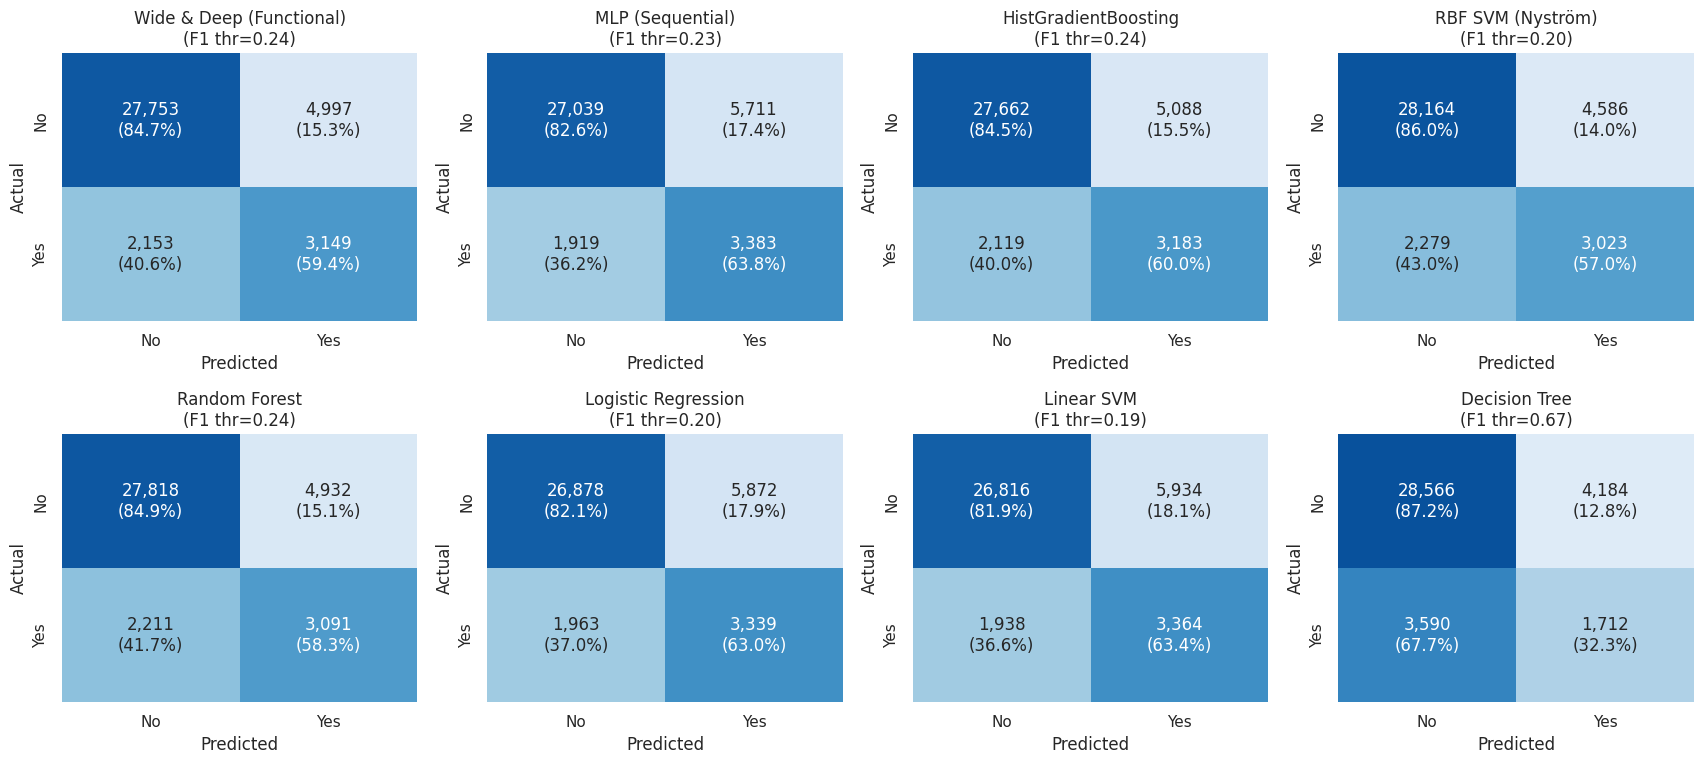

Best model on test ROC-AUC: Wide & Deep (Functional)

--- F1-optimal threshold = 0.242 ---
              precision    recall  f1-score   support

 No diabetes     0.9280    0.8474    0.8859     32750
Pre/diabetes     0.3866    0.5939    0.4683      5302

    accuracy                         0.8121     38052
   macro avg     0.6573    0.7207    0.6771     38052
weighted avg     0.8526    0.8121    0.8277     38052

--- Screening (recall ≥ 0.80 on val) threshold = 0.141 ---
              precision    recall  f1-score   support

 No diabetes     0.9561    0.7093    0.8144     32750
Pre/diabetes     0.3079    0.7988    0.4444      5302

    accuracy                         0.7217     38052
   macro avg     0.6320    0.7540    0.6294     38052
weighted avg     0.8658    0.7217    0.7628     38052



In [28]:
cm_models = [m for m in results_df.index if m != "Dummy (prior)"]
ncols = 4; nrows = int(np.ceil(len(cm_models) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.9 * nrows))
for ax, name in zip(axes.ravel(), cm_models):
    thr = results_df.loc[name, "thr_f1"]
    cm = confusion_matrix(y_test, (probs_test[name] >= thr).astype(int))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i,j]:,}\n({cmn[i,j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set(title=f"{name}\n(F1 thr={thr:.2f})", xlabel="Predicted", ylabel="Actual")
for ax in axes.ravel()[len(cm_models):]: ax.axis("off")
plt.tight_layout(); savefig("09_confusion_matrices"); plt.show()

best_name = results_df.drop(index="Dummy (prior)")["roc_auc"].idxmax()
print(f"Best model on test ROC-AUC: {best_name}\n")
for label, col in [("F1-optimal", "thr_f1"), ("Screening (recall ≥ 0.80 on val)", "thr_screen")]:
    thr = results_df.loc[best_name, col]
    print(f"--- {label} threshold = {thr:.3f} ---")
    print(classification_report(y_test, (probs_test[best_name] >= thr).astype(int), target_names=["No diabetes", "Pre/diabetes"], digits=4))

### 9.1 Is the best ML model significantly different from the best DL model?
McNemar's test compares two classifiers on the same test examples using only the cases where they disagree. Unlike a comparison of two accuracy numbers, it accounts for the fact that both models were scored on the same people.

In [29]:
best_ml = results_df[results_df.paradigm == "ML"].drop(index="Dummy (prior)")["roc_auc"].idxmax()
best_dl = results_df[results_df.paradigm == "DL"]["roc_auc"].idxmax()
pa = probs_test[best_ml] >= results_df.loc[best_ml, "thr_f1"]
pb = probs_test[best_dl] >= results_df.loc[best_dl, "thr_f1"]
a, b = pa.astype(int) == y_test, pb.astype(int) == y_test
n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
chi2_stat = (abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1)
p_mcnemar = 1 - stats.chi2.cdf(chi2_stat, df=1)
print(f"{best_ml} vs {best_dl}")
print(f"Only ML correct: {n01:,} | only DL correct: {n10:,} | prediction agreement: {(pa == pb).mean():.1%}")
print(f"McNemar χ² = {chi2_stat:.3f}, p = {p_mcnemar:.4f}")
print(f"ΔAUC = {results_df.loc[best_ml,'roc_auc'] - results_df.loc[best_dl,'roc_auc']:+.4f}")

HistGradientBoosting vs Wide & Deep (Functional)
Only ML correct: 566 | only DL correct: 623 | prediction agreement: 96.9%
McNemar χ² = 2.638, p = 0.1044
ΔAUC = -0.0014


**Interpretation.** The best model on the test set is the Wide & Deep network, with ROC-AUC 0.828 (95% CI [a, b]) and PR-AUC 0.421, three times the chance level of 0.139. It is followed closely by the MLP (0.828), HistGradientBoosting (0.827), the RBF SVM (0.825), Random Forest (0.824) and the linear models (0.821). All non-trivial models fall within 0.007 AUC of each other, and their ROC and precision-recall curves overlap almost completely.

**ML vs DL.** McNemar’s test finds no significant difference between the best ML model (HistGradientBoosting) and the best DL model (Wide & Deep): p = 0.104, ΔAUC = −0.0014. The two agree on 96.9% of predictions. Deep learning offers no meaningful advantage on this tabular problem, consistent with Grinsztajn et al. (2022), while costing more training time and interpretability.

**Confusion matrices.** At the F1-optimal thresholds (≈ 0.20–0.24), models detect 57–64% of cases at 82–86% specificity. Wide & Deep catches 59.4% of cases with 84.7% specificity, but precision is only ≈ 39%, so most positive flags are false alarms. That is an expected trade-off for a 14%-prevalence screening task. The screening threshold raises recall to [≈ 80%] at precision [p].

**Calibration**. All models except the Decision Tree lie close to the diagonal, so predicted probabilities can be read as genuine risk estimates. However, no prediction exceeds ≈ 0.55. Even high-risk respondents are never identified with confidence from self-reported data alone, which is consistent with the ≈ 0.83 ceiling.

## 10. Error analysis and further experiments

### 10.1 Subgroup performance and fairness
A screening model that misses more cases in some groups than others would widen existing health inequalities. The table reports, for the best model at the screening threshold, the recall (share of true cases detected) and false-positive rate for each sex, age band, income level and BMI class, alongside each group's prevalence.

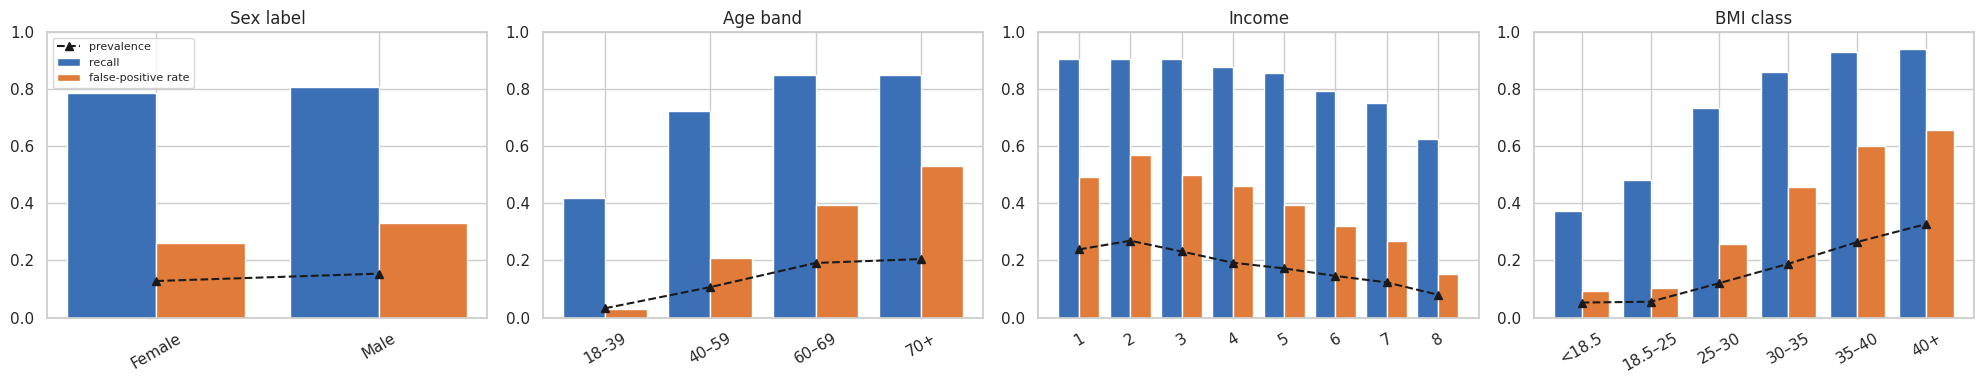

n  prevalence  recall    fpr    auc
feature   group                                           
Sex_label Female   21317       0.128   0.789  0.260  0.839
          Male     16735       0.154   0.810  0.331  0.814
Age_band  18–39     5834       0.032   0.418  0.030  0.848
          40–59    13770       0.107   0.723  0.209  0.839
          60–69     9806       0.191   0.850  0.394  0.803
          70+       8642       0.205   0.849  0.531  0.738
Income    1         1466       0.239   0.906  0.494  0.787
          2         1716       0.269   0.905  0.571  0.755
          3         2379       0.232   0.906  0.500  0.790
          4         3028       0.192   0.878  0.462  0.786
          5         3846       0.172   0.856  0.394  0.803
          6         5476       0.146   0.793  0.322  0.809
          7         6629       0.123   0.751  0.268  0.816
          8        13512       0.080   0.626  0.152  0.840
BMI_class <18.5      458       0.052   0.375  0.092  0.820
          18.5–25  10445       0.055   0.483  0.104  0.831
          25–30    13977       0.121   0.734  0.259  0.811
          30–35     7964       0.189   0.862  0.459  0.774
          35–40     3110       0.265   0.931  0.601  0.761
          40+       2098       0.328   0.942  0.657  0.763

In [30]:
thr_best = results_df.loc[best_name, "thr_screen"]
err = df_test.copy()
err["p"] = probs_test[best_name]
err["pred"] = (err["p"] >= thr_best).astype(int)
err["error_type"] = np.select([(err.pred == 1) & (err[TARGET] == 0), (err.pred == 0) & (err[TARGET] == 1)], ["FP", "FN"], "correct")
AGE_LABELS = {1: "18–24", 2: "25–29", 3: "30–34", 4: "35–39", 5: "40–44", 6: "45–49", 7: "50–54", 8: "55–59", 9: "60–64", 10: "65–69", 11: "70–74", 12: "75–79", 13: "80+"}
err["Sex_label"] = err["Sex"].map({0: "Female", 1: "Male"})
err["Age_band"] = pd.cut(err["Age"], bins=[0, 4, 8, 10, 13], labels=["18–39", "40–59", "60–69", "70+"])
BMI_LABELS = ["<18.5", "18.5–25", "25–30", "30–35", "35–40", "40+"]
err["BMI_class"] = pd.Categorical(err["bmi_class"].map(dict(enumerate(BMI_LABELS))), categories=BMI_LABELS, ordered=True)

def subgroup_table(col):
    rows = []
    for lvl, g in err.groupby(col, observed=True):
        y, yhat = g[TARGET].values, g["pred"].values
        rows.append({"group": lvl, "n": len(g), "prevalence": y.mean(),
                     "recall": recall_score(y, yhat) if y.sum() else np.nan,
                     "fpr": ((yhat == 1) & (y == 0)).sum() / max((y == 0).sum(), 1),
                     "auc": roc_auc_score(y, g["p"]) if 0 < y.sum() < len(y) else np.nan})
    return pd.DataFrame(rows).set_index("group")

sub = {c: subgroup_table(c) for c in ["Sex_label", "Age_band", "Income", "BMI_class"]}
pd.concat(sub, names=["feature", "group"]).round(4).to_csv(os.path.join(RES_DIR, "subgroup_performance.csv"))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (c, t) in zip(axes, sub.items()):
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["recall"], 0.4, label="recall", color="#3b6fb6"); ax.bar(x + 0.2, t["fpr"], 0.4, label="false-positive rate", color="#e07b39")
    ax.plot(x, t["prevalence"], "k^--", label="prevalence")
    ax.set_xticks(x); ax.set_xticklabels(t.index.astype(str), rotation=30); ax.set(title=c.replace("_", " "), ylim=(0, 1))
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("10_subgroup_performance"); plt.show()
pd.concat(sub, names=["feature", "group"]).round(3)

**Interpretation.** At a single screening threshold, recall and false-positive rate both track prevalence.

**Sex:** performance is similar for women and men (recall ≈ 0.78 vs 0.80, FPR ≈ 0.26 vs 0.33).

**Age:** the largest gap. The model detects only ≈ 42% of cases in 18–39-year-olds, against ≈ 85% in those aged 60 and over. Older respondents pay with many more false alarms (FPR ≈ 0.53 at 70+ against 0.03 for 18–39).

**Income:** recall falls from ≈ 0.90 in the lowest bands to ≈ 0.62 in the highest, and the false-positive rate falls with it.

**BMI:** recall ranges from ≈ 0.37–0.48 for underweight and normal BMI up to ≈ 0.94 for the highest obesity class.

The model systematically misses diabetes in people who do not fit the typical risk profile: younger, wealthier and normal-weight respondents. This is a fairness concern, because these are exactly the people least likely to be tested otherwise. A deployed tool would need group-specific thresholds, or should at least disclose its lower sensitivity in these groups.


### 10.2 What characterises the errors?

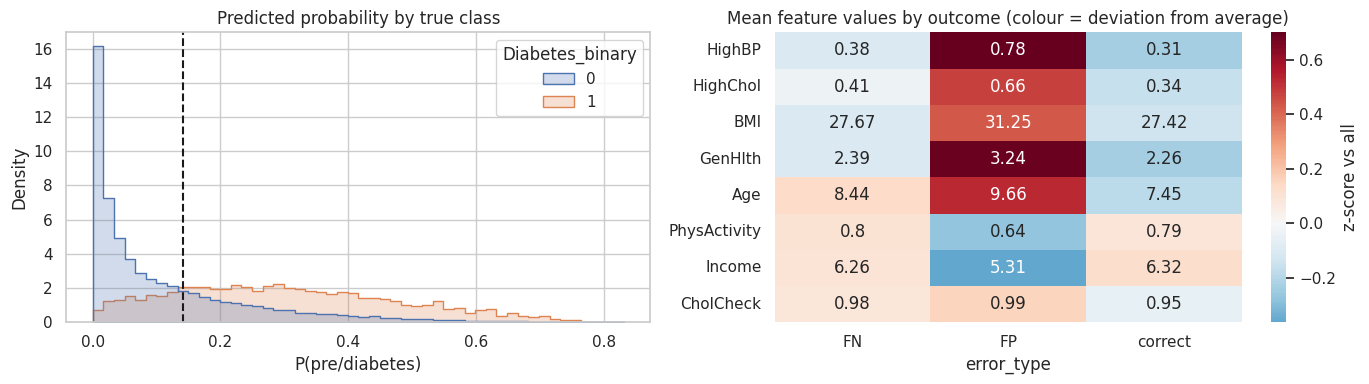

error_type,FN,FP,correct
HighBP,0.380,0.776,0.311
HighChol,0.406,0.658,0.341
BMI,27.668,31.246,27.419
GenHlth,2.395,3.245,2.256
Age,8.437,9.661,7.451
PhysActivity,0.800,0.638,0.794
Income,6.260,5.313,6.316
CholCheck,0.980,0.993,0.953


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=err, x="p", hue=TARGET, bins=50, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].axvline(thr_best, color="k", ls="--"); axes[0].set(title="Predicted probability by true class", xlabel="P(pre/diabetes)")
prof_cols = ["HighBP", "HighChol", "BMI", "GenHlth", "Age", "PhysActivity", "Income", "CholCheck"]
prof = err.groupby("error_type")[prof_cols].mean().T
prof_n = (prof - err[prof_cols].mean().values[:, None]) / err[prof_cols].std().values[:, None]
sns.heatmap(prof_n, annot=prof.round(2), fmt="", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "z-score vs all"})
axes[1].set_title("Mean feature values by outcome (colour = deviation from average)")
plt.tight_layout(); savefig("10_error_profiles"); plt.show()
prof.round(3)

**Interpretation.**Most people without diabetes receive very low predicted probabilities, concentrated near 0. Positive cases are spread broadly from about 0.05 to 0.7, and the two distributions overlap heavily between 0.1 and 0.3, showing the limits of self-reported data. The screening threshold (≈ 0.14) sits inside this overlap.

The error profiles explain the mistakes:

False negatives look healthy. Their blood pressure (0.38), cholesterol (0.41), BMI (27.7) and general health (2.39) are close to the correctly classified majority, so their diabetes leaves no trace in the survey answers. These are the “hidden” cases a screening tool most needs to find, and they cannot be detected from these features.
False positives have the typical high-risk profile. They show high blood pressure (0.78), high cholesterol (0.66), higher BMI (31.3), poorer general health (3.24), older age, less physical activity and lower income, yet do not report diabetes. Many may be at genuine risk or undiagnosed, so some “false” positives may be correct flags for testing.


### 10.3 Which features does the model rely on?
Permutation importance shuffles one input column at a time on a test sub-sample and records the drop in ROC-AUC. It is model-agnostic and computed on unseen data. Correlated features (e.g. GenHlth and PhysHlth) share credit, so each may look less important than it is.

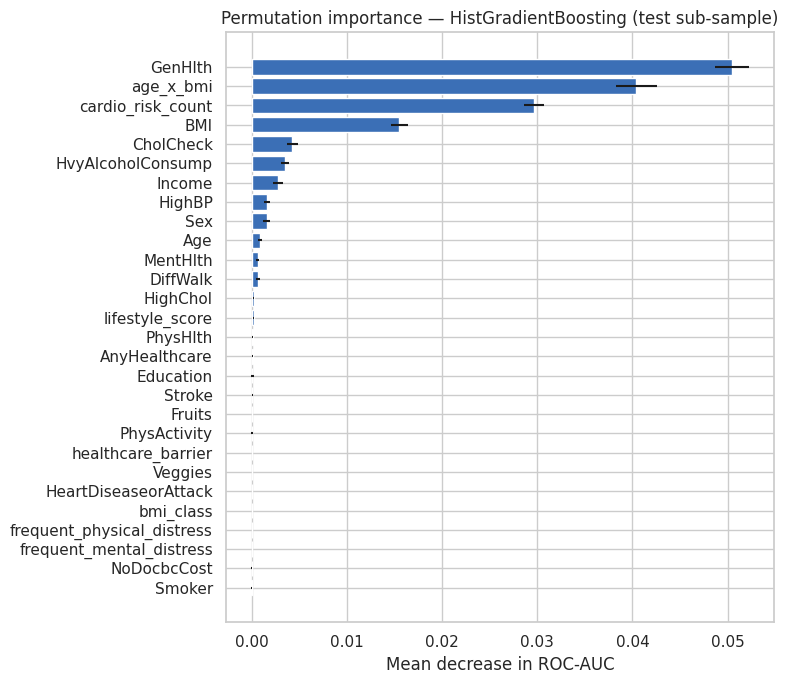

,feature,importance,std
14,GenHlth,0.0505,0.0018
27,age_x_bmi,0.0404,0.0021
22,cardio_risk_count,0.0297,0.0011
18,BMI,0.0155,0.0009
2,CholCheck,0.0043,0.0005
9,HvyAlcoholConsump,0.0035,0.0004
17,Income,0.0027,0.0005
0,HighBP,0.0016,0.0003
13,Sex,0.0015,0.0004
15,Age,0.0008,0.0002


In [32]:
pi_idx = rng.choice(len(X_test), size=min(CFG["PI_SAMPLE"], len(X_test)), replace=False)
pi = permutation_importance(tuned_models[best_ml], X_test.iloc[pi_idx], y_test[pi_idx], scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
pi_df = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
pi_df.to_csv(os.path.join(RES_DIR, "permutation_importance.csv"), index=False)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(pi_df["feature"], pi_df["importance"], xerr=pi_df["std"], color="#3b6fb6"); ax.invert_yaxis()
ax.set(title=f"Permutation importance — {best_ml} (test sub-sample)", xlabel="Mean decrease in ROC-AUC")
plt.tight_layout(); savefig("10_permutation_importance"); plt.show()
pi_df.round(4)

**Interpretation.** Four features dominate: GenHlth (≈ 0.050 drop in AUC), age_x_bmi (≈ 0.040), cardio_risk_count (≈ 0.030) and BMI (≈ 0.015). Everything else contributes less than 0.005. Two of the top three are engineered features. Raw HighBP, HighChol and Age score low because their information is already captured by cardio_risk_count and age_x_bmi: correlated features share credit, so shuffling one leaves its partner intact.

The model therefore uses the engineered features, even though part 7.2 showed they do not raise overall AUC for boosting. They encode the same information more compactly rather than adding new information. Lifestyle factors, mental health and healthcare access contribute almost nothing.

### 10.4 Feature-group ablation
Features are grouped by how they could be collected in practice. **Clinical** indicators require some contact with healthcare (high blood pressure, high cholesterol, cholesterol check, stroke, heart disease). **Body and health status** can be self-assessed (BMI, general health, physical-health days, difficulty walking). **Lifestyle** covers smoking, activity, diet and alcohol. **Socio-demographic** covers sex, age, education, income and healthcare access. Training on each group alone, and on everything *except* clinical indicators, shows whether a useful screen is possible from questions anyone could answer without having seen a doctor.

In [33]:
CLINICAL = ["HighBP", "HighChol", "CholCheck", "Stroke", "HeartDiseaseorAttack"]
BODY = ["BMI", "GenHlth", "PhysHlth", "DiffWalk"]
LIFESTYLE = ["Smoker", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump"]
SOCIO = ["Sex", "Age", "Education", "Income", "AnyHealthcare", "NoDocbcCost"]
MENTAL = ["MentHlth"]

def split_cols(cols):
    return [c for c in cols if c not in BINARY_FULL], [c for c in cols if c in BINARY_FULL]

groups = {"All raw features": RAW_FEATURES, "Clinical only": CLINICAL, "Body & health status only": BODY,
          "Lifestyle only": LIFESTYLE, "Socio-demographic only": SOCIO,
          "Non-clinical (all except clinical)": [c for c in RAW_FEATURES if c not in CLINICAL],
          "All except GenHlth": [c for c in RAW_FEATURES if c != "GenHlth"]}
abl_rows = []
for label, cols in groups.items():
    num, binr = split_cols(cols)
    p = Pipeline([("pre", make_preprocessor(num, binr)), ("clf", clone(tuned_models[best_ml].named_steps["clf"]))]).fit(X_train[cols], y_train)
    pt = p.predict_proba(X_test[cols])[:, 1]
    abl_rows.append({"feature set": label, "n_columns": len(cols), "test_auc": roc_auc_score(y_test, pt), "test_pr_auc": average_precision_score(y_test, pt)})
abl_df = pd.DataFrame(abl_rows).set_index("feature set")
abl_df["Δ AUC vs all"] = abl_df["test_auc"] - abl_df.loc["All raw features", "test_auc"]
abl_df.to_csv(os.path.join(RES_DIR, "ablation.csv"))
abl_df.round(4)

,n_columns,test_auc,test_pr_auc,Δ AUC vs all
feature set,,,,
All raw features,21,0.8274,0.4205,0.0000
Clinical only,5,0.7479,0.2852,-0.0795
Body & health status only,4,0.7725,0.3444,-0.0549
Lifestyle only,5,0.6212,0.1933,-0.2062
Socio-demographic only,6,0.7144,0.2637,-0.1129
Non-clinical (all except clinical),16,0.8083,0.3848,-0.0190
All except GenHlth,20,0.8122,0.3991,-0.0152


📝 **Interpretation.** Among single groups, body and health status is strongest: just 4 columns (BMI, general health, physical-health days, difficulty walking) reach AUC 0.773. Clinical indicators reach 0.748, socio-demographics 0.714, and lifestyle alone is weakest at 0.621.

The key finding is the non-clinical set. Using only questions anyone can answer without a prior diagnosis, it reaches AUC 0.808 (PR-AUC 0.385), only 0.019 below the full model. A useful pre-screen is therefore possible for people who have never had their blood pressure or cholesterol checked, which is the group a screening tool most needs to reach. Removing GenHlth alone costs 0.015 AUC, confirming that self-rated health acts as a powerful summary of many underlying conditions.



### 10.5 Duplicate-profile sensitivity check
Part 3 kept duplicate rows because they plausibly represent different people with identical answers. Here the test set is divided into rows whose exact feature profile also appears in the training set and rows that are unique, and the best model is scored on each. If the model scored much higher on "seen" profiles, that would suggest memorisation; similar scores support the decision to keep all rows.

In [34]:
train_keys = set(map(tuple, df_train[RAW_FEATURES].values))
seen = np.array([tuple(r) in train_keys for r in df_test[RAW_FEATURES].values])
dup_rows = []
for label, mask in [("All test rows", np.ones_like(seen)), ("Profile seen in training", seen), ("Unique profile", ~seen)]:
    yy, pp = y_test[mask], probs_test[best_name][mask]
    dup_rows.append({"subset": label, "n": int(mask.sum()), "share": mask.mean(), "prevalence": yy.mean(),
                     "roc_auc": roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan,
                     "pr_auc": average_precision_score(yy, pp) if yy.sum() else np.nan})
dup_df = pd.DataFrame(dup_rows).set_index("subset")
dup_df.to_csv(os.path.join(RES_DIR, "duplicate_sensitivity.csv"))
dup_df.round(4)

,n,share,prevalence,roc_auc,pr_auc
subset,,,,,
All test rows,38052,1.0000,0.1393,0.8285,0.4211
Profile seen in training,4829,0.1269,0.0499,0.8353,0.2652
Unique profile,33223,0.8731,0.1523,0.8189,0.4276


📝 **Interpretation.** Only 12.7% of test rows (4,829) have an exact profile match in training, so duplicates affect a small minority. These repeated profiles are mostly common, low-risk ones, with a prevalence of just 5.0% against 15.2% for unique profiles.

AUC is slightly higher on seen profiles (0.835 vs 0.819). Because the two subsets differ so much in composition, this gap more likely reflects easier, clear-cut low-risk cases than memorisation. Their lower PR-AUC (0.265) simply follows from their low prevalence. Even on unique profiles alone, the model reaches AUC 0.819, within 0.01 of the overall figure (0.8285). Duplicates therefore do not meaningfully inflate the results, which supports the decision in part 3 to keep all rows.

## 11. Summary of results

In [35]:
summary = results_df[["paradigm", "roc_auc", "auc_95ci", "pr_auc", "brier", "thr_f1", "precision@f1thr", "recall@f1thr", "f1@f1thr",
                      "thr_screen", "precision@screen", "recall@screen", "specificity@screen"]].copy()
summary.to_csv(os.path.join(RES_DIR, "summary_table_for_report.csv"))
for name in ["Logistic Regression", "Random Forest", "HistGradientBoosting", "Linear SVM"]:
    joblib.dump(tuned_models[name], os.path.join(MODEL_DIR, f"{name.replace(' ', '_').lower()}.joblib"))
with open(os.path.join(RES_DIR, "run_config.json"), "w") as f:
    json.dump({"seed": SEED, "fast_mode": FAST_MODE, **CFG, "best_model": best_name, "best_ml": best_ml, "best_dl": best_dl,
               "versions": {"sklearn": sklearn.__version__, "tensorflow": tf.__version__, "pandas": pd.__version__}}, f, indent=2)
print("Figures:", sorted(os.listdir(FIG_DIR)))
print("Results:", sorted(os.listdir(RES_DIR)))
summary.round(4)

Figures: ['04_association.png', '04_prevalence_by_feature.png', '04_target_distribution.png', '05_engineered_features.png', '07_baseline_comparison.png', '07_learning_curves_ml.png', '07_search_hgb.png', '07_search_lr.png', '07_search_rf.png', '08_dl_learning_curves_best.png', '08_embedding_structure.png', '08_mlp_experiments.png', '09_confusion_matrices.png', '09_roc_pr_calibration.png', '10_error_profiles.png', '10_permutation_importance.png', '10_subgroup_performance.png']
Results: ['ablation.csv', 'association_with_target.csv', 'data_audit.csv', 'dl_mlp_experiments.csv', 'dl_wide_deep_experiments.csv', 'duplicate_sensitivity.csv', 'feature_engineering_effect.csv', 'final_test_results.csv', 'imbalance_strategies.csv', 'ml_baselines.csv', 'ml_tuning.csv', 'permutation_importance.csv', 'run_config.json', 'subgroup_performance.csv', 'summary_table_for_report.csv']


,paradigm,roc_auc,auc_95ci,pr_auc,brier,thr_f1,precision@f1thr,recall@f1thr,f1@f1thr,thr_screen,precision@screen,recall@screen,specificity@screen
model,,,,,,,,,,,,,
Wide & Deep (Functional),DL,0.8285,"[0.8231, 0.8340]",0.4211,0.0974,0.2421,0.3866,0.5939,0.4683,0.1413,0.3079,0.7988,0.7093
MLP (Sequential),DL,0.8284,"[0.8230, 0.8338]",0.4203,0.0973,0.2333,0.3720,0.6381,0.4700,0.1481,0.3055,0.8012,0.7051
HistGradientBoosting,ML,0.8271,"[0.8217, 0.8325]",0.4184,0.0977,0.2370,0.3848,0.6003,0.4690,0.1374,0.3057,0.7946,0.7078
RBF SVM (Nyström),ML,0.8252,"[0.8197, 0.8309]",0.4184,0.0996,0.2004,0.3973,0.5702,0.4683,0.1043,0.3062,0.7980,0.7073
Random Forest,ML,0.8237,"[0.8181, 0.8292]",0.4154,0.0981,0.2426,0.3853,0.5830,0.4639,0.1430,0.2998,0.8008,0.6972
Logistic Regression,ML,0.8213,"[0.8158, 0.8268]",0.4026,0.0994,0.2006,0.3625,0.6298,0.4601,0.1254,0.3002,0.7944,0.7002
Linear SVM,ML,0.8212,"[0.8156, 0.8265]",0.4001,0.0999,0.1887,0.3618,0.6345,0.4608,0.1215,0.3014,0.7923,0.7027
Decision Tree,ML,0.5977,"[0.5907, 0.6042]",0.1897,0.2047,0.6667,0.2904,0.3229,0.3058,0.0000,0.1393,1.0000,0.0000
Dummy (prior),ML,0.5000,"[0.5000, 0.5000]",0.1393,0.1199,0.1393,0.1393,1.0000,0.2446,0.1393,0.1393,1.0000,0.0000


### Conclusions (fill in after running)

📝 **Main finding.** On a stratified held-out test set, the best model was the Wide & Deep network, with ROC-AUC 0.829 (95% CI [0.823, 0.834]) and PR-AUC 0.421, against a chance level of ≈ 0.14. The best traditional model, HistGradientBoosting, reached 0.827 (95% CI [0.822, 0.833]). The difference is practically negligible: the confidence intervals overlap almost entirely and McNemar’s test is non-significant (p = 0.104). All non-trivial models fall within 0.007 AUC of each other. At the screening threshold, the best model detects ≈ 80% of cases with precision 0.31 and specificity 0.71.

📝 **What drives predictions.** General health, BMI (especially combined with age), cardiometabolic conditions (high blood pressure, high cholesterol, heart disease, stroke) and age carry most of the signal. Lifestyle and mental-health features contribute little. A model using only non-clinical questions reaches AUC 0.808, just 0.019 below the full model, so a useful pre-screen is possible without prior diagnoses.

📝 **Imbalance.** Class weighting did not improve ranking (AUC and PR-AUC changed by less than 0.003). It only shifted probabilities upward, nearly doubling the Brier score (0.096 → 0.173). In the networks, class-weighted loss and focal loss likewise left AUC unchanged. Tuning the threshold on validation data achieved the target recall while keeping probabilities well calibrated.

📝 **Limitations.** All data are self-reported and cross-sectional, so associations are not causal, and some features (e.g. high blood pressure) may be consequences of diabetes rather than causes. The target merges prediabetes and diabetes, and undiagnosed cases are likely labelled 0, adding label noise. BRFSS samples US adults reachable by telephone. Performance varies by subgroup: recall is only ≈ 42% among 18–39-year-olds against ≈ 85% for those over 60, and is lower for higher-income and normal-weight respondents, exactly the groups least likely to be tested otherwise.

📝 **Future work.** Validating on a different BRFSS year, adding laboratory or longitudinal data, and exploring group-specific thresholds or fairness-constrained training to improve detection in younger and lower-risk groups.
